# Análisis distribucional de intensidades de BRISC

**Objetivo específico 1.** Comparar las distribuciones de intensidad de las imágenes de resonancia magnética cerebral, considerando la imagen completa, la región tumoral y la región no tumoral, según el tipo de tumor y el plano anatómico.

Se examinan histogramas de intensidad normalizados por imagen y medidas descriptivas para las tres regiones de análisis. Las comparaciones principales se realizan mediante DISCO y pruebas post-hoc de Energy Distance. Como análisis complementario, se consideran Kruskal–Wallis y Mann–Whitney para resúmenes por imagen. La unidad estadística de análisis corresponde a cada imagen del conjunto depurado de entrenamiento de BRISC.

## 1. Configuración y criterios de preprocesamiento

Se utiliza la región válida $R_i$, definida al excluir las componentes de intensidad menor o igual que 15 conectadas con los bordes de la imagen (conectividad de ocho vecinos). La región tumoral se obtiene binarizando la máscara con un umbral de 127; la región no tumoral corresponde al complemento de esta dentro de $R_i$.

Cada imagen constituye una observación estadística. Los histogramas se normalizan individualmente para evitar que la cantidad de píxeles de cada región determine su ponderación.

In [1]:
# Importaciones y configuración general

from pathlib import Path
from itertools import combinations
from IPython.display import display

import json
import math
import platform
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from scipy import ndimage
from scipy.spatial.distance import pdist
from scipy.stats import (
    skew,
    kurtosis,
    kruskal,
    mannwhitneyu,
)
from statsmodels.stats.multitest import multipletests
from tqdm import tqdm


pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)


# Semilla aleatoria
RANDOM_SEED = 2026
rng = np.random.default_rng(RANDOM_SEED)


# Rutas de entrada y salida relativas a la raíz del repositorio.
def localizar_raiz_repositorio():
    """Localiza la raíz del repositorio a partir del directorio de ejecución."""
    actual = Path.cwd().resolve()
    for candidato in (actual, *actual.parents):
        if (candidato / "notebooks" / "OE1").is_dir():
            return candidato
    raise FileNotFoundError(
        "No se encontró la raíz del repositorio (notebooks/OE1). "
        "Iniciar JupyterLab desde la raíz del repositorio o uno de sus subdirectorios."
    )


REPO_ROOT = localizar_raiz_repositorio()
BASE_DIR = REPO_ROOT / "data" / "BRISC2025" / "segmentation_task" / "train"
IMAGES_DIR = BASE_DIR / "images"
MASKS_DIR = BASE_DIR / "masks"

if not IMAGES_DIR.is_dir() or not MASKS_DIR.is_dir():
    raise FileNotFoundError(
        "No se encontraron los pares BRISC depurados en "
        "data/BRISC2025/segmentation_task/train/{images,masks}."
    )

OUTPUT_DIR = REPO_ROOT / "results" / "OE1" / "analisis_distribucional_DISCO"
TABLES_DIR = OUTPUT_DIR / "tablas"
FIGURES_DIR = OUTPUT_DIR / "figuras"

for directory in (OUTPUT_DIR, TABLES_DIR, FIGURES_DIR):
    directory.mkdir(parents=True, exist_ok=True)


# Formatos admitidos
IMAGE_EXTENSIONS = {
    ".png",
    ".jpg",
    ".jpeg",
    ".bmp",
    ".tif",
    ".tiff",
}


# Definición de regiones
BACKGROUND_THRESHOLD = 15
MASK_THRESHOLD = 127
MIN_PIXELS_PER_REGION = 10

CONNECTIVITY_STRUCTURE = np.ones(
    (3, 3),
    dtype=bool,
)


# Opciones:
# "none", "minmax_valid" o "zscore_valid"
NORMALIZATION = "none"


# Histogramas medios por imagen
N_INTENSITY_BINS = 128


# Análisis principal: DISCO / Energy Distance
DISCO_DISTANCE_EXPONENT = 1.0
N_DISCO_PERMUTATIONS = 999
N_ENERGY_PAIRWISE_PERMUTATIONS = 999
DISCO_STRATIFIED_PERMUTATIONS = True

# Análisis secundario
SECONDARY_TEST_METRICS = [
    "median",
    "iqr",
    "skewness",
    "kurtosis",
]

# Gráficos
SAVE_FIGURES = True
FIGURE_DPI = 180
BOXPLOT_METRIC = "median"
MAX_AFFECTED_EXAMPLES = 12


# Nivel de significación
ALPHA = 0.05


TUMOR_LABELS = {
    "gl": "Glioma",
    "me": "Meningioma",
    "pi": "Pituitario",
}

PLANE_LABELS = {
    "ax": "Axial",
    "co": "Coronal",
    "sa": "Sagital",
}

REGION_LABELS = {
    "complete": "Imagen completa",
    "tumor": "Región tumoral",
    "non_tumor": "Región no tumoral",
}

SUMMARY_METRICS = [
    "mean",
    "std",
    "median",
    "minimum",
    "maximum",
    "q1",
    "q3",
    "iqr",
    "skewness",
    "kurtosis",
]


print(
    f"Umbral de fondo aplicado: "
    f"{BACKGROUND_THRESHOLD}"
)

print(
    "Conectividad utilizada: "
    "ocho vecinos"
)

Umbral de fondo aplicado: 15
Conectividad utilizada: ocho vecinos


## 2. Indexación y correspondencia de archivos

Se identifican las imágenes y máscaras mediante los códigos de tumor, plano anatómico e identificador contenidos en sus nombres. Se registran los pares disponibles, los archivos sin correspondencia y las posibles duplicaciones de claves.

In [2]:
FILENAME_PATTERN = re.compile(
    (
        r"brisc2025_train_"
        r"(?P<image_id>\d+)_"
        r"(?P<tumor_type>gl|me|pi)_"
        r"(?P<plane>ax|co|sa)_t1"
    ),
    flags=re.IGNORECASE,
)


def extract_metadata(path):
    match = FILENAME_PATTERN.search(
        path.stem.lower()
    )

    if match is None:
        return None

    metadata = match.groupdict()

    image_id = metadata["image_id"]
    tumor_type = (
        metadata["tumor_type"].lower()
    )
    plane = metadata["plane"].lower()

    return {
        "image_id": image_id,
        "tumor_type": tumor_type,
        "plane": plane,
        "pair_key": (
            f"{image_id}_"
            f"{tumor_type}_"
            f"{plane}"
        ),
    }


def index_directory(
    directory,
    role,
):
    if not directory.exists():
        raise FileNotFoundError(
            f"No existe la carpeta: {directory}"
        )

    records = []
    unrecognized = []

    for path in sorted(
        directory.iterdir()
    ):
        if (
            not path.is_file()
            or path.suffix.lower()
            not in IMAGE_EXTENSIONS
        ):
            continue

        metadata = extract_metadata(path)

        if metadata is None:
            unrecognized.append(
                str(path)
            )
            continue

        records.append({
            **metadata,
            f"{role}_path": str(path),
            f"{role}_filename": path.name,
        })

    indexed = pd.DataFrame(records)

    if indexed.empty:
        raise ValueError(
            "No se encontraron archivos "
            f"reconocibles en {directory}."
        )

    duplicate_mask = indexed.duplicated(
        "pair_key",
        keep=False,
    )

    duplicates = (
        indexed.loc[duplicate_mask]
        .sort_values("pair_key")
        .copy()
    )

    return (
        indexed,
        pd.DataFrame({
            "path": unrecognized
        }),
        duplicates,
    )

Se indexan los archivos de cada modalidad y se construye la tabla de pares válidos.

In [3]:
images_index, unrecognized_images, duplicated_images = (
    index_directory(
        IMAGES_DIR,
        role="image",
    )
)

masks_index, unrecognized_masks, duplicated_masks = (
    index_directory(
        MASKS_DIR,
        role="mask",
    )
)


if not duplicated_images.empty:
    display(duplicated_images)

    raise ValueError(
        "Se detectaron imágenes duplicadas "
        "para una misma clave."
    )


if not duplicated_masks.empty:
    display(duplicated_masks)

    raise ValueError(
        "Se detectaron máscaras duplicadas "
        "para una misma clave."
    )


pairs_df = images_index.merge(
    masks_index,
    on=[
        "pair_key",
        "image_id",
        "tumor_type",
        "plane",
    ],
    how="outer",
    indicator=True,
)


unmatched_images = pairs_df.loc[
    pairs_df["_merge"] == "left_only",
    [
        "pair_key",
        "image_id",
        "tumor_type",
        "plane",
        "image_path",
        "image_filename",
    ],
].copy()


unmatched_masks = pairs_df.loc[
    pairs_df["_merge"] == "right_only",
    [
        "pair_key",
        "image_id",
        "tumor_type",
        "plane",
        "mask_path",
        "mask_filename",
    ],
].copy()


pairs_df = (
    pairs_df.loc[
        pairs_df["_merge"] == "both"
    ]
    .drop(columns="_merge")
    .sort_values([
        "tumor_type",
        "plane",
        "image_id",
    ])
    .reset_index(drop=True)
)


print(
    f"Imágenes reconocidas: "
    f"{len(images_index):,}"
)

print(
    f"Máscaras reconocidas: "
    f"{len(masks_index):,}"
)

print(
    f"Pares válidos: "
    f"{len(pairs_df):,}"
)

print(
    f"Imágenes sin máscara: "
    f"{len(unmatched_images):,}"
)

print(
    f"Máscaras sin imagen: "
    f"{len(unmatched_masks):,}"
)

print(
    "Imágenes con nombre no reconocido: "
    f"{len(unrecognized_images):,}"
)

print(
    "Máscaras con nombre no reconocido: "
    f"{len(unrecognized_masks):,}"
)


display(
    pd.crosstab(
        pairs_df["tumor_type"].map(
            TUMOR_LABELS
        ),
        pairs_df["plane"].map(
            PLANE_LABELS
        ),
        margins=True,
    )
)


unmatched_images.to_csv(
    TABLES_DIR
    / "imagenes_sin_mascara.csv",
    index=False,
)

unmatched_masks.to_csv(
    TABLES_DIR
    / "mascaras_sin_imagen.csv",
    index=False,
)

unrecognized_images.to_csv(
    TABLES_DIR
    / "imagenes_nombre_no_reconocido.csv",
    index=False,
)

unrecognized_masks.to_csv(
    TABLES_DIR
    / "mascaras_nombre_no_reconocido.csv",
    index=False,
)

pairs_df.to_csv(
    TABLES_DIR
    / "pares_imagen_mascara.csv",
    index=False,
)

Imágenes reconocidas: 3,792
Máscaras reconocidas: 3,792
Pares válidos: 3,792
Imágenes sin máscara: 0
Máscaras sin imagen: 0
Imágenes con nombre no reconocido: 0
Máscaras con nombre no reconocido: 0


plane,Axial,Coronal,Sagital,All
tumor_type,,,,
Glioma,394,430,323,1147
Meningioma,348,400,458,1206
Pituitario,424,502,513,1439
All,1166,1332,1294,3792


## 3. Definición de regiones y resúmenes de intensidad

Se construye la región válida de cada imagen mediante propagación binaria desde sus bordes y se obtienen las regiones completa, tumoral y no tumoral. Para cada región se calculan las medidas descriptivas y los recuentos de píxeles, incluidos los píxeles tumorales conservados.

In [4]:
def load_grayscale(path):
    with Image.open(path) as image:
        return np.asarray(
            image.convert("L")
        )


def external_background_connected_to_border(
    image,
    threshold,
):
    low_intensity = (
        image <= threshold
    )

    seed = np.zeros_like(
        low_intensity,
        dtype=bool,
    )

    seed[0, :] = low_intensity[0, :]
    seed[-1, :] = low_intensity[-1, :]
    seed[:, 0] = low_intensity[:, 0]
    seed[:, -1] = low_intensity[:, -1]

    return ndimage.binary_propagation(
        seed,
        structure=CONNECTIVITY_STRUCTURE,
        mask=low_intensity,
    )


def valid_mask_for_threshold(
    image,
    threshold,
):
    background = (
        external_background_connected_to_border(
            image,
            threshold=threshold,
        )
    )

    return ~background


def build_region_masks(
    image,
    segmentation_mask,
):
    if image.shape != segmentation_mask.shape:
        raise ValueError(
            "Dimensiones incompatibles: "
            f"imagen {image.shape} y "
            f"máscara {segmentation_mask.shape}."
        )

    tumor_raw = (
        segmentation_mask
        > MASK_THRESHOLD
    )

    valid = valid_mask_for_threshold(
        image,
        threshold=BACKGROUND_THRESHOLD,
    )

    regions = {
        "complete": valid,
        "tumor": tumor_raw & valid,
        "non_tumor": (~tumor_raw) & valid,
    }

    return (
        regions,
        tumor_raw,
    )


def normalize_intensities(
    image,
    valid_mask,
):
    transformed = image.astype(
        np.float64,
        copy=True,
    )

    valid_values = transformed[
        valid_mask
    ]

    if valid_values.size == 0:
        raise ValueError(
            "La imagen no contiene "
            "píxeles válidos."
        )

    if NORMALIZATION == "none":
        return transformed

    if NORMALIZATION == "minmax_valid":
        minimum = valid_values.min()
        maximum = valid_values.max()
        scale = maximum - minimum

        if scale == 0:
            raise ValueError(
                "No es posible aplicar min-max "
                "a una imagen constante."
            )

        return (
            transformed - minimum
        ) / scale

    if NORMALIZATION == "zscore_valid":
        mean_value = valid_values.mean()
        std_value = valid_values.std(
            ddof=0
        )

        if std_value == 0:
            raise ValueError(
                "No es posible estandarizar "
                "una imagen constante."
            )

        return (
            transformed - mean_value
        ) / std_value

    raise ValueError(
        "NORMALIZATION debe ser "
        "'none', 'minmax_valid' "
        "o 'zscore_valid'."
    )


def safe_skew(values):
    if (
        values.size < 3
        or np.all(values == values[0])
    ):
        return np.nan

    return float(
        skew(
            values,
            bias=False,
            nan_policy="omit",
        )
    )


def safe_kurtosis(values):
    if (
        values.size < 4
        or np.all(values == values[0])
    ):
        return np.nan

    return float(
        kurtosis(
            values,
            fisher=True,
            bias=False,
            nan_policy="omit",
        )
    )


def summarize_values(values):
    values = np.asarray(
        values,
        dtype=np.float64,
    )

    values = values[
        np.isfinite(values)
    ]

    if (
        values.size
        < MIN_PIXELS_PER_REGION
    ):
        raise ValueError(
            "La región contiene solo "
            f"{values.size} píxeles válidos; "
            "se requieren al menos "
            f"{MIN_PIXELS_PER_REGION}."
        )

    q1, median_value, q3 = np.quantile(
        values,
        [0.25, 0.50, 0.75],
    )

    return {
        "n_pixels": int(values.size),
        "mean": float(
            np.mean(values)
        ),
        "std": float(
            np.std(
                values,
                ddof=1,
            )
        ),
        "median": float(
            median_value
        ),
        "minimum": float(
            np.min(values)
        ),
        "maximum": float(
            np.max(values)
        ),
        "q1": float(q1),
        "q3": float(q3),
        "iqr": float(q3 - q1),
        "skewness": safe_skew(values),
        "kurtosis": safe_kurtosis(values),
    }


def analyze_pair(row):
    image = load_grayscale(
        row.image_path
    )

    segmentation_mask = load_grayscale(
        row.mask_path
    )

    regions, tumor_raw = build_region_masks(
        image,
        segmentation_mask,
    )

    transformed_image = normalize_intensities(
        image,
        regions["complete"],
    )

    valid_pixels = int(
        regions["complete"].sum()
    )

    tumor_pixels = int(
        tumor_raw.sum()
    )

    if valid_pixels == 0:
        raise ValueError(
            "La imagen no contiene "
            "región válida."
        )

    if tumor_pixels == 0:
        raise ValueError(
            "La máscara tumoral no contiene "
            "píxeles positivos."
        )

    common = {
        "pair_key": row.pair_key,
        "image_id": row.image_id,
        "tumor_type": row.tumor_type,
        "tumor_label": (
            TUMOR_LABELS[
                row.tumor_type
            ]
        ),
        "plane": row.plane,
        "plane_label": (
            PLANE_LABELS[
                row.plane
            ]
        ),
        "image_path": row.image_path,
        "mask_path": row.mask_path,
        "height": int(
            image.shape[0]
        ),
        "width": int(
            image.shape[1]
        ),
        "valid_pixels": valid_pixels,
        "valid_fraction": (
            valid_pixels
            / image.size
        ),
    }

    records = []

    for (
        region_name,
        region_mask,
    ) in regions.items():
        summary = summarize_values(
            transformed_image[
                region_mask
            ]
        )

        records.append({
            **common,
            "region": region_name,
            "region_label": (
                REGION_LABELS[
                    region_name
                ]
            ),
            **summary,
        })

    return records

In [5]:
summary_records = []
processing_errors = []

for row in tqdm(
    pairs_df.itertuples(index=False),
    total=len(pairs_df),
    desc="Calculando resúmenes por imagen",
):
    try:
        summary_records.extend(
            analyze_pair(row)
        )

    except Exception as error:
        processing_errors.append({
            "pair_key": row.pair_key,
            "image_id": row.image_id,
            "tumor_type": row.tumor_type,
            "plane": row.plane,
            "image_path": row.image_path,
            "mask_path": row.mask_path,
            "error_type": (
                type(error).__name__
            ),
            "error_message": str(error),
        })


summary_df = pd.DataFrame(
    summary_records
)

errors_df = pd.DataFrame(
    processing_errors
)


if summary_df.empty:
    raise RuntimeError(
        "No fue posible procesar ningún "
        "par imagen-máscara."
    )


summary_df.to_csv(
    TABLES_DIR
    / "resumenes_por_imagen.csv",
    index=False,
)

errors_df.to_csv(
    TABLES_DIR
    / "errores_procesamiento.csv",
    index=False,
)


n_successful_images = (
    summary_df["pair_key"].nunique()
)


print(
    "Imágenes procesadas correctamente: "
    f"{n_successful_images:,}"
)

print(
    f"Imágenes con error: "
    f"{len(errors_df):,}"
)

print(
    "Registros regionales generados: "
    f"{len(summary_df):,}"
)


display(
    summary_df.head()
)

if not errors_df.empty:
    display(
        errors_df.head(20)
    )

Calculando resúmenes por imagen: 100%|█████████████████████████████████████████████| 3792/3792 [01:44<00:00, 36.34it/s]


Imágenes procesadas correctamente: 3,792
Imágenes con error: 0
Registros regionales generados: 11,376


,pair_key,image_id,tumor_type,tumor_label,plane,plane_label,image_path,mask_path,height,width,valid_pixels,valid_fraction,region,region_label,n_pixels,mean,std,median,minimum,maximum,q1,q3,iqr,skewness,kurtosis
0,00001_gl_ax,00001,gl,Glioma,ax,Axial,K:\Tesis\Github\data\BRISC2025\segmentation_ta...,K:\Tesis\Github\data\BRISC2025\segmentation_ta...,512,512,122210,0.466194,complete,Imagen completa,122210,81.800925,38.225404,77.0,0.0,255.0,62.0,89.0,27.0,1.559735,3.198880
1,00001_gl_ax,00001,gl,Glioma,ax,Axial,K:\Tesis\Github\data\BRISC2025\segmentation_ta...,K:\Tesis\Github\data\BRISC2025\segmentation_ta...,512,512,122210,0.466194,tumor,Región tumoral,16345,64.255063,13.908566,63.0,11.0,146.0,55.0,72.0,17.0,0.656724,1.545372
2,00001_gl_ax,00001,gl,Glioma,ax,Axial,K:\Tesis\Github\data\BRISC2025\segmentation_ta...,K:\Tesis\Github\data\BRISC2025\segmentation_ta...,512,512,122210,0.466194,non_tumor,Región no tumoral,105865,84.509914,40.025566,79.0,0.0,255.0,65.0,91.0,26.0,1.398289,2.516860
3,00002_gl_ax,00002,gl,Glioma,ax,Axial,K:\Tesis\Github\data\BRISC2025\segmentation_ta...,K:\Tesis\Github\data\BRISC2025\segmentation_ta...,512,512,117445,0.448017,complete,Imagen completa,117445,53.532786,26.038691,52.0,0.0,255.0,43.0,60.0,17.0,1.567857,4.772011
4,00002_gl_ax,00002,gl,Glioma,ax,Axial,K:\Tesis\Github\data\BRISC2025\segmentation_ta...,K:\Tesis\Github\data\BRISC2025\segmentation_ta...,512,512,117445,0.448017,tumor,Región tumoral,15797,46.632399,8.458112,46.0,12.0,90.0,41.0,52.0,11.0,0.343397,0.881508


## 4. Estadística descriptiva por imagen

Se resumen media, desviación estándar, mediana, extremos, cuartiles, rango intercuartílico, asimetría y curtosis de Fisher de cada región. Las tablas se presentan globalmente y según tipo de tumor, plano anatómico y su combinación.

In [6]:
def grouped_descriptive_table(
    data,
    group_columns,
):
    aggregation = {
        metric: [
            "count",
            "mean",
            "std",
            "median",
            "min",
            "max",
        ]
        for metric in SUMMARY_METRICS
    }

    result = (
        data
        .groupby(
            [
                *group_columns,
                "region_label",
            ],
            observed=True,
        )
        .agg(aggregation)
        .reset_index()
    )

    result.columns = [
        "_".join(
            str(part)
            for part in column
            if str(part)
        )
        if isinstance(
            column,
            tuple,
        )
        else column
        for column in result.columns
    ]

    return result


descriptive_global = (
    grouped_descriptive_table(
        summary_df,
        [],
    )
)

descriptive_by_tumor = (
    grouped_descriptive_table(
        summary_df,
        ["tumor_label"],
    )
)

descriptive_by_plane = (
    grouped_descriptive_table(
        summary_df,
        ["plane_label"],
    )
)

descriptive_by_tumor_plane = (
    grouped_descriptive_table(
        summary_df,
        [
            "tumor_label",
            "plane_label",
        ],
    )
)


descriptive_global.to_csv(
    TABLES_DIR
    / "descriptivos_globales.csv",
    index=False,
)

descriptive_by_tumor.to_csv(
    TABLES_DIR
    / "descriptivos_por_tipo_tumor.csv",
    index=False,
)

descriptive_by_plane.to_csv(
    TABLES_DIR
    / "descriptivos_por_plano.csv",
    index=False,
)

descriptive_by_tumor_plane.to_csv(
    TABLES_DIR
    / "descriptivos_por_tumor_y_plano.csv",
    index=False,
)


SELECTED_METRIC = "median"

selected_descriptives = (
    summary_df
    .groupby(
        [
            "region_label",
            "tumor_label",
            "plane_label",
        ],
        observed=True,
    )[SELECTED_METRIC]
    .agg(
        n="count",
        mean="mean",
        std="std",
        median="median",
        q1=lambda values: (
            values.quantile(0.25)
        ),
        q3=lambda values: (
            values.quantile(0.75)
        ),
        minimum="min",
        maximum="max",
    )
    .reset_index()
)


print(
    "Resumen descriptivo de la "
    "medida por imagen: "
    f"{SELECTED_METRIC}"
)

display(
    selected_descriptives
)

Resumen descriptivo de la medida por imagen: median


,region_label,tumor_label,plane_label,n,mean,std,median,q1,q3,minimum,maximum
0,Imagen completa,Glioma,Axial,394,61.350254,10.581522,60.0,53.250,68.00,40.0,101.0
1,Imagen completa,Glioma,Coronal,430,62.230233,8.260644,63.0,57.000,67.00,36.0,85.0
2,Imagen completa,Glioma,Sagital,323,67.755418,11.705453,66.0,60.000,75.00,35.0,104.0
3,Imagen completa,Meningioma,Axial,348,79.830460,15.795979,77.0,71.000,88.00,43.0,164.0
4,Imagen completa,Meningioma,Coronal,400,74.030000,6.857599,74.0,69.000,79.00,51.0,101.0
5,Imagen completa,Meningioma,Sagital,458,74.054585,11.333384,73.0,66.250,81.00,42.0,125.0
6,Imagen completa,Pituitario,Axial,424,68.156840,7.085066,68.0,63.000,73.00,49.0,86.0
7,Imagen completa,Pituitario,Coronal,502,72.370518,6.726639,72.0,68.000,77.00,47.0,95.0
8,Imagen completa,Pituitario,Sagital,513,68.584795,9.032338,68.0,62.000,75.00,42.0,91.0
9,Región no tumoral,Glioma,Axial,394,61.446701,10.755599,60.0,53.000,68.00,40.0,103.0


## 5. Histogramas normalizados y curvas medias

Se calcula un histograma de 128 intervalos para cada imagen y región, normalizado para que sus frecuencias sumen uno. Las curvas de los grupos se obtienen promediando estos histogramas individuales, tanto globalmente como por tipo de tumor y plano anatómico.

In [7]:
def determine_histogram_edges(
    data,
    n_bins,
):
    if NORMALIZATION == "none":
        return np.linspace(
            0,
            256,
            n_bins + 1,
        )

    lower = float(
        data["minimum"].min()
    )

    upper = float(
        data["maximum"].max()
    )

    if (
        not np.isfinite(lower)
        or not np.isfinite(upper)
        or lower >= upper
    ):
        raise ValueError(
            "No fue posible determinar "
            "un rango de intensidades válido."
        )

    return np.linspace(
        lower,
        upper,
        n_bins + 1,
    )


def update_histogram_accumulator(
    accumulator,
    key,
    values,
    bin_edges,
):
    counts, _ = np.histogram(
        values,
        bins=bin_edges,
    )

    total = counts.sum()

    if total == 0:
        return

    normalized = (
        counts.astype(np.float64)
        / total
    )

    if key not in accumulator:
        accumulator[key] = {
            "sum_mass": np.zeros_like(
                normalized,
                dtype=np.float64,
            ),
            "n_images": 0,
        }

    accumulator[key][
        "sum_mass"
    ] += normalized

    accumulator[key][
        "n_images"
    ] += 1


def compute_mean_image_histograms(
    pairs,
    bin_edges,
):
    accumulator = {}
    histogram_errors = []

    for row in tqdm(
        pairs.itertuples(index=False),
        total=len(pairs),
        desc=(
            "Calculando histogramas "
            "medios"
        ),
    ):
        try:
            image = load_grayscale(
                row.image_path
            )

            segmentation_mask = (
                load_grayscale(
                    row.mask_path
                )
            )

            regions, _ = build_region_masks(
                image,
                segmentation_mask,
            )

            transformed_image = (
                normalize_intensities(
                    image,
                    regions["complete"],
                )
            )

            for (
                region_name,
                region_mask,
            ) in regions.items():
                values = transformed_image[
                    region_mask
                ]

                values = values[
                    np.isfinite(values)
                ]

                if (
                    values.size
                    < MIN_PIXELS_PER_REGION
                ):
                    continue

                keys = [
                    (
                        "global",
                        "Todos",
                        region_name,
                    ),
                    (
                        "tumor_type",
                        TUMOR_LABELS[
                            row.tumor_type
                        ],
                        region_name,
                    ),
                    (
                        "plane",
                        PLANE_LABELS[
                            row.plane
                        ],
                        region_name,
                    ),
                ]

                for key in keys:
                    update_histogram_accumulator(
                        accumulator,
                        key,
                        values,
                        bin_edges,
                    )

        except Exception as error:
            histogram_errors.append({
                "pair_key": row.pair_key,
                "image_id": row.image_id,
                "error_type": (
                    type(error).__name__
                ),
                "error_message": (
                    str(error)
                ),
            })

    centers = (
        bin_edges[:-1]
        + bin_edges[1:]
    ) / 2

    bin_widths = np.diff(
        bin_edges
    )

    records = []

    for (
        grouping,
        group,
        region,
    ), values in accumulator.items():
        mean_mass = (
            values["sum_mass"]
            / values["n_images"]
        )

        mean_density = (
            mean_mass
            / bin_widths
        )

        for (
            center,
            density,
        ) in zip(
            centers,
            mean_density,
        ):
            records.append({
                "grouping": grouping,
                "group": group,
                "region": region,
                "region_label": (
                    REGION_LABELS[
                        region
                    ]
                ),
                "intensity": float(
                    center
                ),
                "density": float(
                    density
                ),
                "n_images": int(
                    values["n_images"]
                ),
            })

    return (
        pd.DataFrame(records),
        pd.DataFrame(
            histogram_errors
        ),
    )


histogram_edges = (
    determine_histogram_edges(
        summary_df,
        N_INTENSITY_BINS,
    )
)


density_df, histogram_errors_df = (
    compute_mean_image_histograms(
        pairs_df,
        histogram_edges,
    )
)


density_df.to_csv(
    TABLES_DIR
    / (
        "curvas_densidad_"
        "histogramas_medios.csv"
    ),
    index=False,
)

histogram_errors_df.to_csv(
    TABLES_DIR
    / "errores_histogramas.csv",
    index=False,
)


display(
    density_df.head()
)

Calculando histogramas medios: 100%|███████████████████████████████████████████████| 3792/3792 [01:01<00:00, 61.72it/s]


,grouping,group,region,region_label,intensity,density,n_images
0,global,Todos,complete,Imagen completa,1.0,0.000424,3792
1,global,Todos,complete,Imagen completa,3.0,0.000900,3792
2,global,Todos,complete,Imagen completa,5.0,0.001801,3792
3,global,Todos,complete,Imagen completa,7.0,0.002356,3792
4,global,Todos,complete,Imagen completa,9.0,0.002540,3792


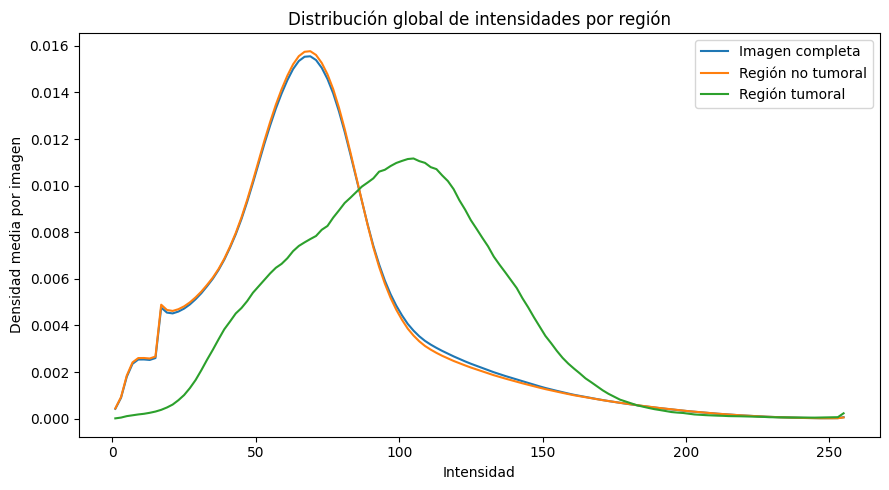

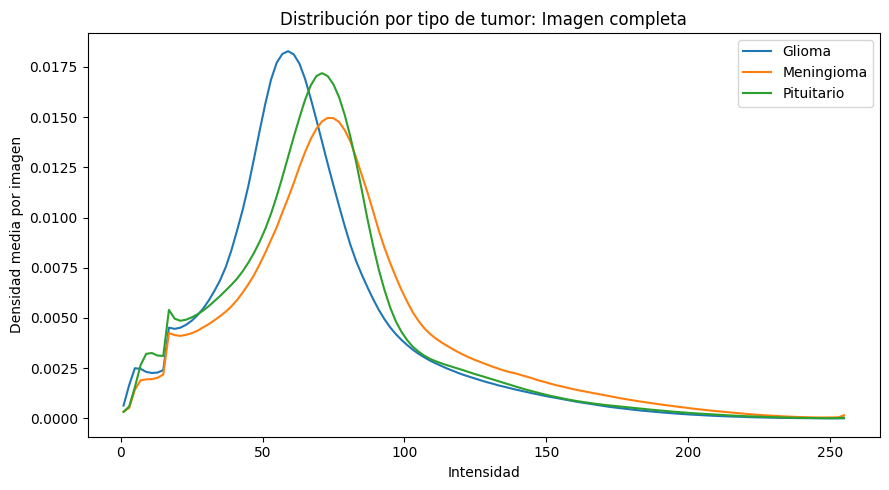

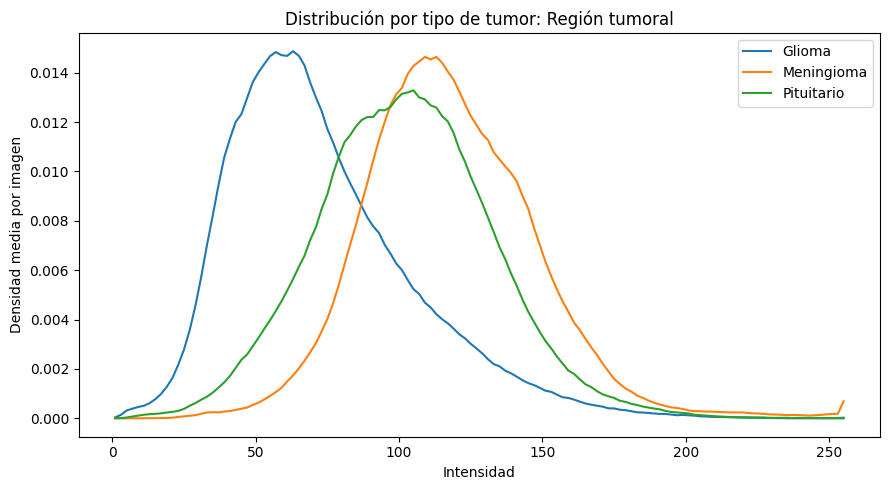

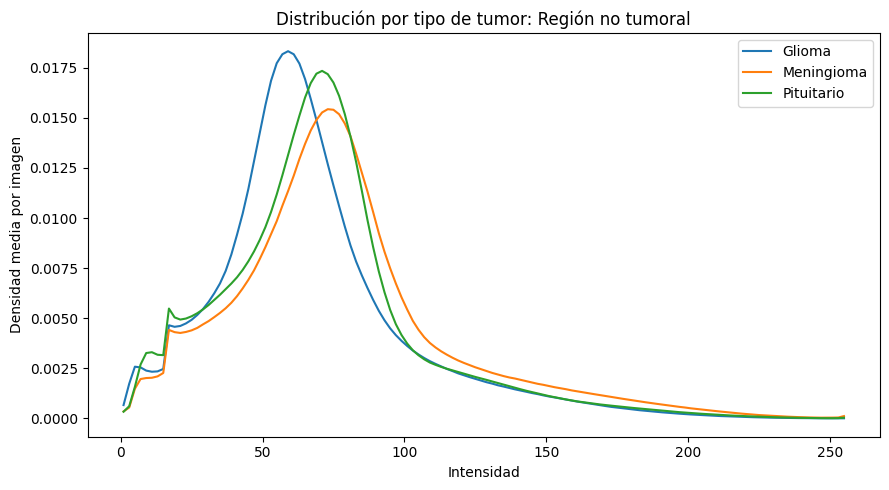

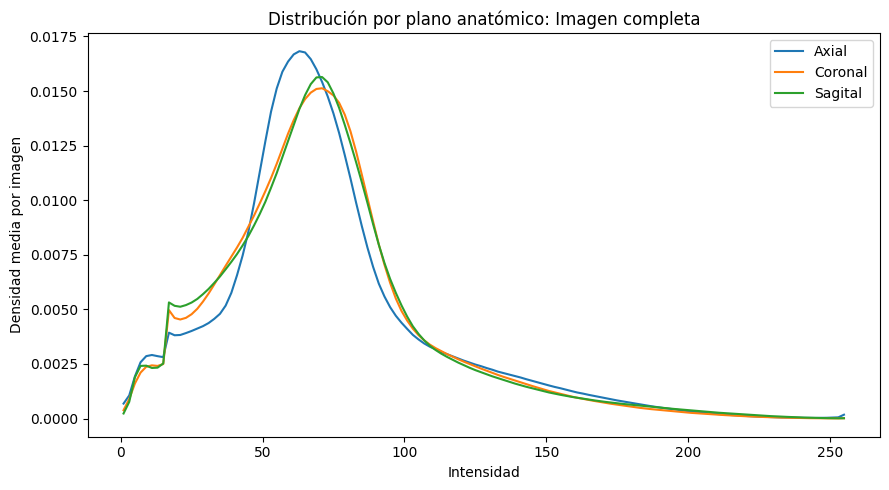

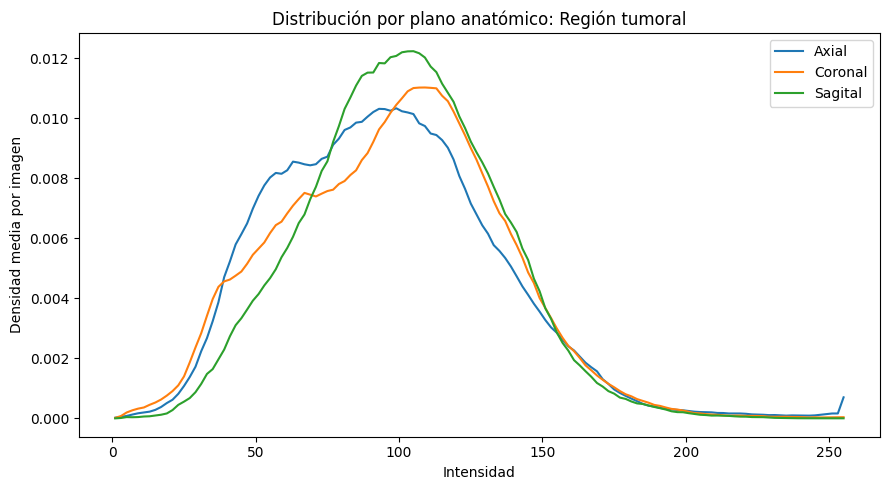

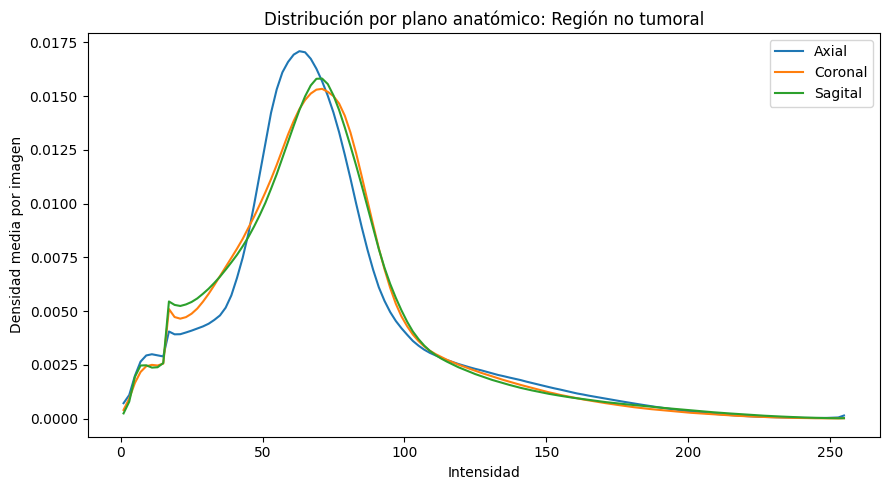

In [8]:
def finish_figure(filename):
    plt.tight_layout()

    if SAVE_FIGURES:
        plt.savefig(
            FIGURES_DIR / filename,
            dpi=FIGURE_DPI,
            bbox_inches="tight",
        )

    plt.show()


global_density = density_df.loc[
    density_df["grouping"] == "global"
]


plt.figure(
    figsize=(9, 5)
)

for (
    region_name,
    region_data,
) in global_density.groupby(
    "region",
    observed=True,
):
    region_data = region_data.sort_values(
        "intensity"
    )

    plt.plot(
        region_data["intensity"],
        region_data["density"],
        label=REGION_LABELS[
            region_name
        ],
    )


plt.xlabel("Intensidad")
plt.ylabel(
    "Densidad media por imagen"
)
plt.title(
    "Distribución global de "
    "intensidades por región"
)
plt.legend()

finish_figure(
    "densidad_global_por_region.png"
)


for (
    region_name,
    region_label,
) in REGION_LABELS.items():
    subset = density_df.loc[
        (
            density_df["grouping"]
            == "tumor_type"
        )
        & (
            density_df["region"]
            == region_name
        )
    ]

    plt.figure(
        figsize=(9, 5)
    )

    for (
        group_name,
        group_data,
    ) in subset.groupby(
        "group",
        observed=True,
    ):
        group_data = (
            group_data.sort_values(
                "intensity"
            )
        )

        plt.plot(
            group_data["intensity"],
            group_data["density"],
            label=group_name,
        )

    plt.xlabel("Intensidad")
    plt.ylabel(
        "Densidad media por imagen"
    )
    plt.title(
        "Distribución por tipo "
        f"de tumor: {region_label}"
    )
    plt.legend()

    finish_figure(
        f"densidad_tumor_{region_name}.png"
    )


for (
    region_name,
    region_label,
) in REGION_LABELS.items():
    subset = density_df.loc[
        (
            density_df["grouping"]
            == "plane"
        )
        & (
            density_df["region"]
            == region_name
        )
    ]

    plt.figure(
        figsize=(9, 5)
    )

    for (
        group_name,
        group_data,
    ) in subset.groupby(
        "group",
        observed=True,
    ):
        group_data = (
            group_data.sort_values(
                "intensity"
            )
        )

        plt.plot(
            group_data["intensity"],
            group_data["density"],
            label=group_name,
        )

    plt.xlabel("Intensidad")
    plt.ylabel(
        "Densidad media por imagen"
    )
    plt.title(
        "Distribución por plano "
        f"anatómico: {region_label}"
    )
    plt.legend()

    finish_figure(
        f"densidad_plano_{region_name}.png"
    )

## 6. Diagramas de caja

Se representan los resúmenes de intensidad por imagen según los grupos de tumor y plano anatómico. La supresión de valores atípicos se aplica únicamente a la representación gráfica, sin excluir observaciones del análisis.

<Figure size 800x500 with 0 Axes>

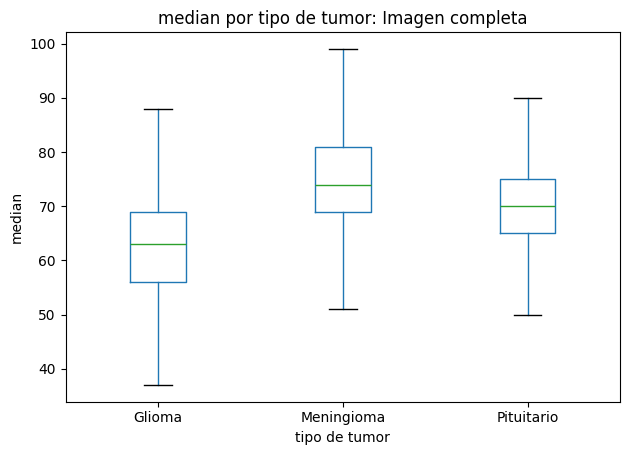

<Figure size 800x500 with 0 Axes>

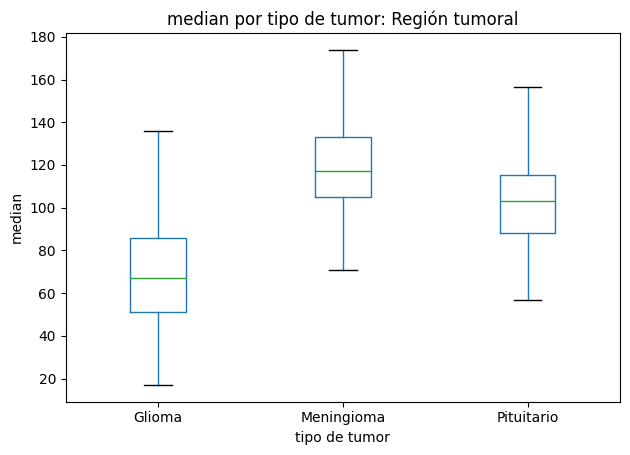

<Figure size 800x500 with 0 Axes>

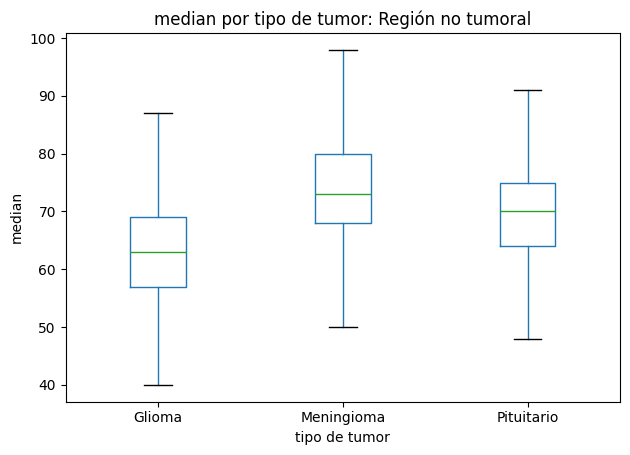

<Figure size 800x500 with 0 Axes>

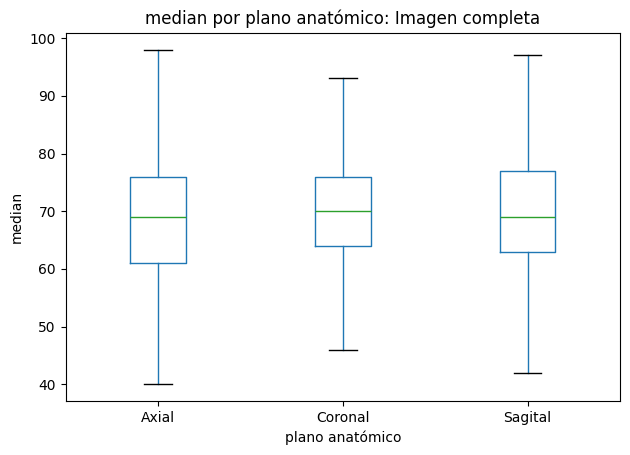

<Figure size 800x500 with 0 Axes>

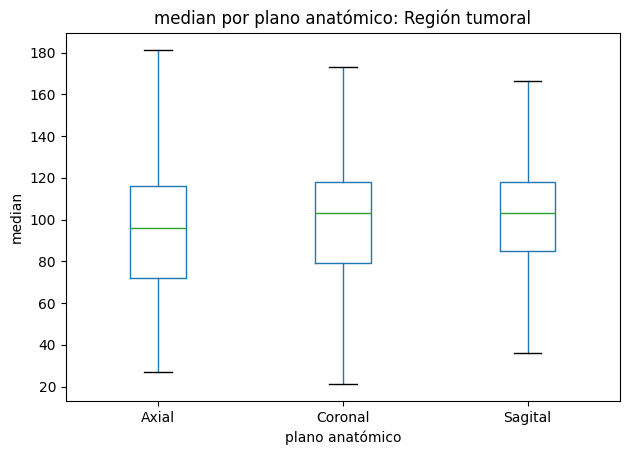

<Figure size 800x500 with 0 Axes>

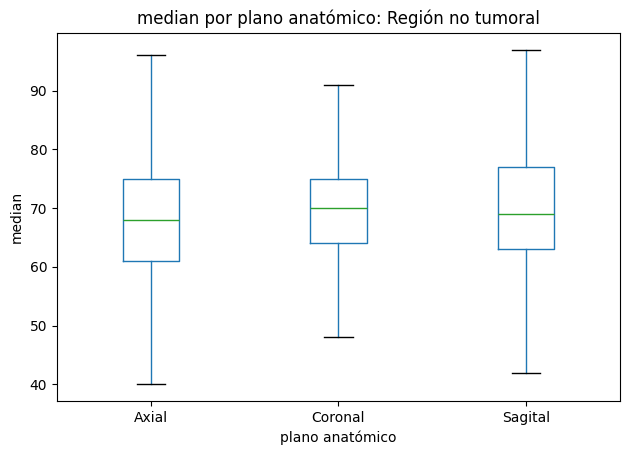

In [9]:
if (
    BOXPLOT_METRIC
    not in SUMMARY_METRICS
):
    raise ValueError(
        "BOXPLOT_METRIC debe pertenecer "
        f"a {SUMMARY_METRICS}."
    )


def plot_boxplots(
    data,
    metric,
    group_column,
    group_title,
    filename_prefix,
):
    for (
        region_name,
        region_label,
    ) in REGION_LABELS.items():
        subset = data.loc[
            data["region"] == region_name,
            [
                group_column,
                metric,
            ],
        ].dropna()

        plt.figure(
            figsize=(8, 5)
        )

        subset.boxplot(
            column=metric,
            by=group_column,
            grid=False,
            showfliers=False,
        )

        plt.suptitle("")

        plt.title(
            f"{metric} por "
            f"{group_title}: "
            f"{region_label}"
        )

        plt.xlabel(
            group_title
        )

        plt.ylabel(
            metric
        )

        finish_figure(
            f"{filename_prefix}_"
            f"{region_name}_"
            f"{metric}.png"
        )


plot_boxplots(
    summary_df,
    metric=BOXPLOT_METRIC,
    group_column="tumor_label",
    group_title="tipo de tumor",
    filename_prefix="boxplot_tumor",
)


plot_boxplots(
    summary_df,
    metric=BOXPLOT_METRIC,
    group_column="plane_label",
    group_title="plano anatómico",
    filename_prefix="boxplot_plano",
)

## 7. Contrastes distribucionales: DISCO y Energy Distance

Cada imagen se representa mediante el vector de 128 frecuencias relativas de su histograma. La prueba DISCO utiliza la distancia euclidiana con exponente $\alpha=1$ para comparar las distribuciones de estos vectores según tipo de tumor y plano anatómico, en las tres regiones.

Se realizan 999 permutaciones estratificadas por el factor no evaluado y se ajustan conjuntamente los seis valores $p$ mediante Holm. Para los contrastes globales significativos, se efectúan comparaciones por pares con Energy Distance y 999 permutaciones, con corrección de Holm dentro de cada contraste global.

In [10]:
def normalized_histogram(values, bin_edges):
    counts, _ = np.histogram(values, bins=bin_edges)
    total = int(counts.sum())
    if total == 0:
        raise ValueError("El histograma no contiene píxeles.")
    return counts.astype(np.float64) / total


def compute_individual_histograms(pairs, bin_edges):
    distribution_data = {
        region_name: {"histograms": [], "metadata": []}
        for region_name in REGION_LABELS
    }
    processing_errors = []

    for row in tqdm(
        pairs.itertuples(index=False),
        total=len(pairs),
        desc="Calculando histogramas individuales",
    ):
        try:
            image = load_grayscale(row.image_path)
            segmentation_mask = load_grayscale(row.mask_path)
            regions, _ = build_region_masks(image, segmentation_mask)
            transformed_image = normalize_intensities(
                image,
                regions["complete"],
            )

            for region_name, region_mask in regions.items():
                values = transformed_image[region_mask]
                values = values[np.isfinite(values)]
                if values.size < MIN_PIXELS_PER_REGION:
                    continue

                histogram = normalized_histogram(values, bin_edges)
                histogram_row = len(
                    distribution_data[region_name]["histograms"]
                )
                distribution_data[region_name]["histograms"].append(histogram)
                distribution_data[region_name]["metadata"].append({
                    "histogram_row": histogram_row,
                    "pair_key": row.pair_key,
                    "image_id": row.image_id,
                    "tumor_type": row.tumor_type,
                    "tumor_label": TUMOR_LABELS[row.tumor_type],
                    "plane": row.plane,
                    "plane_label": PLANE_LABELS[row.plane],
                })
        except Exception as error:
            processing_errors.append({
                "pair_key": row.pair_key,
                "image_id": row.image_id,
                "error_type": type(error).__name__,
                "error_message": str(error),
            })

    for region_name in distribution_data:
        histograms = distribution_data[region_name]["histograms"]
        distribution_data[region_name]["histograms"] = (
            np.vstack(histograms)
            if histograms
            else np.empty((0, len(bin_edges) - 1), dtype=np.float64)
        )
        distribution_data[region_name]["metadata"] = pd.DataFrame(
            distribution_data[region_name]["metadata"]
        )

    return distribution_data, pd.DataFrame(processing_errors)


individual_distribution_data, individual_histogram_errors_df = (
    compute_individual_histograms(pairs_df, histogram_edges)
)

metadata_tables = []
for region_name, data in individual_distribution_data.items():
    histograms = data["histograms"]
    metadata = data["metadata"].copy()
    metadata.insert(0, "region", region_name)
    metadata.insert(1, "region_label", REGION_LABELS[region_name])
    metadata_tables.append(metadata)

    np.save(
        TABLES_DIR / f"histogramas_normalizados_{region_name}.npy",
        histograms,
    )

individual_histogram_metadata_df = pd.concat(
    metadata_tables,
    ignore_index=True,
)

individual_histogram_metadata_df.to_csv(
    TABLES_DIR / "metadatos_histogramas_normalizados_por_imagen.csv",
    index=False,
)

individual_histogram_errors_df.to_csv(
    TABLES_DIR / "errores_histogramas_individuales.csv",
    index=False,
)

np.save(TABLES_DIR / "histogram_bin_edges.npy", histogram_edges)

for region_name, data in individual_distribution_data.items():
    print(
        f"{REGION_LABELS[region_name]}: "
        f"{len(data['metadata']):,} histogramas"
    )

print(
    "Errores en histogramas individuales: "
    f"{len(individual_histogram_errors_df):,}"
)

Calculando histogramas individuales: 100%|█████████████████████████████████████████| 3792/3792 [00:49<00:00, 76.42it/s]


Imagen completa: 3,792 histogramas
Región tumoral: 3,792 histogramas
Región no tumoral: 3,792 histogramas
Errores en histogramas individuales: 0


In [11]:
def encode_labels(values):
    values = np.asarray(values)
    levels = np.array(sorted(pd.unique(values)), dtype=object)
    mapping = {level: index for index, level in enumerate(levels)}
    codes = np.array([mapping[value] for value in values], dtype=np.int16)
    return codes, levels


def pair_indices(n_observations):
    i_index, j_index = np.triu_indices(n_observations, k=1)
    return (
        i_index.astype(np.int32, copy=False),
        j_index.astype(np.int32, copy=False),
    )


def disco_components_from_condensed(
    condensed_distances,
    pair_i,
    pair_j,
    group_codes,
):
    group_codes = np.asarray(group_codes, dtype=np.int16)
    n_observations = len(group_codes)
    counts = np.bincount(group_codes).astype(np.float64)
    n_groups = len(counts)

    if n_groups < 2:
        raise ValueError("DISCO requiere al menos dos grupos.")
    if np.any(counts < 2):
        raise ValueError("Cada grupo debe contener al menos dos imágenes.")

    group_i = group_codes[pair_i]
    group_j = group_codes[pair_j]
    same_group = group_i == group_j

    within_pair_sums = np.bincount(
        group_i[same_group],
        weights=condensed_distances[same_group],
        minlength=n_groups,
    ).astype(np.float64)

    # W_alpha = suma de las distancias internas superiores / n_k
    within_dispersion = float(np.sum(within_pair_sums / counts))

    # T_alpha = suma de todas las distancias del triángulo superior / N
    total_dispersion = float(
        np.sum(condensed_distances, dtype=np.float64) / n_observations
    )

    between_dispersion = float(
        max(total_dispersion - within_dispersion, 0.0)
    )

    if within_dispersion <= 0:
        f_statistic = np.inf
    else:
        f_statistic = float(
            (between_dispersion / (n_groups - 1))
            / (within_dispersion / (n_observations - n_groups))
        )

    return {
        "n_images": int(n_observations),
        "n_groups": int(n_groups),
        "between_dispersion": between_dispersion,
        "within_dispersion": within_dispersion,
        "total_dispersion": total_dispersion,
        "disco_f": f_statistic,
    }


def permute_codes(group_codes, random_generator, strata_codes=None):
    group_codes = np.asarray(group_codes, dtype=np.int16)
    if strata_codes is None:
        return random_generator.permutation(group_codes)

    strata_codes = np.asarray(strata_codes)
    permuted = group_codes.copy()
    for stratum in np.unique(strata_codes):
        indices = np.flatnonzero(strata_codes == stratum)
        permuted[indices] = random_generator.permutation(permuted[indices])
    return permuted


def disco_permutation_test(
    condensed_distances,
    pair_i,
    pair_j,
    group_codes,
    n_permutations,
    random_generator,
    strata_codes=None,
):
    observed = disco_components_from_condensed(
        condensed_distances,
        pair_i,
        pair_j,
        group_codes,
    )

    permutation_statistics = np.empty(n_permutations, dtype=np.float64)

    for permutation_index in tqdm(
        range(n_permutations),
        desc="Permutaciones DISCO",
        leave=False,
    ):
        permuted_codes = permute_codes(
            group_codes,
            random_generator,
            strata_codes=strata_codes,
        )
        permutation_statistics[permutation_index] = (
            disco_components_from_condensed(
                condensed_distances,
                pair_i,
                pair_j,
                permuted_codes,
            )["disco_f"]
        )

    p_value = float(
        (1 + np.count_nonzero(
            permutation_statistics >= observed["disco_f"]
        ))
        / (n_permutations + 1)
    )

    return observed, p_value, permutation_statistics


def energy_distance_from_condensed(
    condensed_distances,
    pair_i,
    pair_j,
    group_codes,
):
    group_codes = np.asarray(group_codes, dtype=np.int16)
    if len(np.unique(group_codes)) != 2:
        raise ValueError("Energy Distance requiere exactamente dos grupos.")

    counts = np.bincount(group_codes, minlength=2).astype(np.float64)
    n_1, n_2 = counts
    group_i = group_codes[pair_i]
    group_j = group_codes[pair_j]

    same_1 = (group_i == 0) & (group_j == 0)
    same_2 = (group_i == 1) & (group_j == 1)
    between = group_i != group_j

    within_sum_1 = float(np.sum(condensed_distances[same_1], dtype=np.float64))
    within_sum_2 = float(np.sum(condensed_distances[same_2], dtype=np.float64))
    between_sum = float(np.sum(condensed_distances[between], dtype=np.float64))

    g_11 = 2.0 * within_sum_1 / (n_1 ** 2)
    g_22 = 2.0 * within_sum_2 / (n_2 ** 2)
    g_12 = between_sum / (n_1 * n_2)

    return float(max(2.0 * g_12 - g_11 - g_22, 0.0))


def energy_permutation_test(
    histograms,
    labels,
    exponent,
    n_permutations,
    random_generator,
    strata=None,
):
    labels = np.asarray(labels)
    group_codes, levels = encode_labels(labels)
    if len(levels) != 2:
        raise ValueError("Se requieren exactamente dos grupos.")

    distances = pdist(histograms, metric="euclidean")
    if exponent != 1:
        distances = distances ** exponent
    distances = distances.astype(np.float32, copy=False)
    pair_i, pair_j = pair_indices(len(histograms))

    observed = energy_distance_from_condensed(
        distances,
        pair_i,
        pair_j,
        group_codes,
    )

    strata_codes = encode_labels(strata)[0] if strata is not None else None
    permutation_statistics = np.empty(n_permutations, dtype=np.float64)

    for permutation_index in tqdm(
        range(n_permutations),
        desc="Permutaciones Energy",
        leave=False,
    ):
        permuted_codes = permute_codes(
            group_codes,
            random_generator,
            strata_codes=strata_codes,
        )
        permutation_statistics[permutation_index] = (
            energy_distance_from_condensed(
                distances,
                pair_i,
                pair_j,
                permuted_codes,
            )
        )

    p_value = float(
        (1 + np.count_nonzero(permutation_statistics >= observed))
        / (n_permutations + 1)
    )

    return {
        "levels": levels,
        "energy_distance": observed,
        "p_value": p_value,
        "permutation_statistics": permutation_statistics,
    }

In [12]:
factor_definitions = [
    {
        "factor": "Tipo de tumor",
        "factor_slug": "tipo_tumor",
        "group_column": "tumor_label",
        "strata_column": "plane_label",
    },
    {
        "factor": "Plano anatómico",
        "factor_slug": "plano",
        "group_column": "plane_label",
        "strata_column": "tumor_label",
    },
]

disco_global_records = []
disco_null_distributions = {}
disco_distance_cache = {}

for region_name, region_data in individual_distribution_data.items():
    histograms = region_data["histograms"]
    metadata = region_data["metadata"].reset_index(drop=True)
    if len(histograms) < 2:
        continue

    print(f"\nCalculando distancias para {REGION_LABELS[region_name]}...")
    condensed_distances = pdist(histograms, metric="euclidean")
    if DISCO_DISTANCE_EXPONENT != 1:
        condensed_distances = condensed_distances ** DISCO_DISTANCE_EXPONENT
    condensed_distances = condensed_distances.astype(np.float32, copy=False)
    pair_i, pair_j = pair_indices(len(histograms))

    disco_distance_cache[region_name] = {
        "distances": condensed_distances,
        "pair_i": pair_i,
        "pair_j": pair_j,
    }

    for factor_definition in factor_definitions:
        group_values = metadata[factor_definition["group_column"]].to_numpy()
        group_codes, levels = encode_labels(group_values)

        if DISCO_STRATIFIED_PERMUTATIONS:
            strata_values = metadata[factor_definition["strata_column"]].to_numpy()
            strata_codes, _ = encode_labels(strata_values)
        else:
            strata_codes = None

        print(
            "DISCO: "
            f"{factor_definition['factor']} — "
            f"{REGION_LABELS[region_name]}"
        )

        random_generator = np.random.default_rng(
            RANDOM_SEED + len(disco_global_records)
        )

        observed, p_value, permutation_statistics = disco_permutation_test(
            condensed_distances,
            pair_i,
            pair_j,
            group_codes,
            n_permutations=N_DISCO_PERMUTATIONS,
            random_generator=random_generator,
            strata_codes=strata_codes,
        )

        group_sizes = {
            str(level): int(np.count_nonzero(group_values == level))
            for level in levels
        }

        disco_global_records.append({
            "factor": factor_definition["factor"],
            "factor_slug": factor_definition["factor_slug"],
            "group_column": factor_definition["group_column"],
            "strata_column": (
                factor_definition["strata_column"]
                if DISCO_STRATIFIED_PERMUTATIONS
                else ""
            ),
            "region": region_name,
            "region_label": REGION_LABELS[region_name],
            "n_images": observed["n_images"],
            "n_groups": observed["n_groups"],
            "group_sizes": json.dumps(group_sizes, ensure_ascii=False),
            "distance_exponent": DISCO_DISTANCE_EXPONENT,
            "between_dispersion": observed["between_dispersion"],
            "within_dispersion": observed["within_dispersion"],
            "total_dispersion": observed["total_dispersion"],
            "disco_f": observed["disco_f"],
            "n_permutations": N_DISCO_PERMUTATIONS,
            "p_value": p_value,
        })

        disco_null_distributions[(factor_definition["factor_slug"], region_name)] = {
            "factor": factor_definition["factor"],
            "region_label": REGION_LABELS[region_name],
            "observed": observed["disco_f"],
            "permutations": permutation_statistics,
        }

disco_global_results = pd.DataFrame(disco_global_records)
disco_global_results["p_holm"] = np.nan
valid_p = disco_global_results["p_value"].notna()
if valid_p.any():
    disco_global_results.loc[valid_p, "p_holm"] = multipletests(
        disco_global_results.loc[valid_p, "p_value"],
        alpha=ALPHA,
        method="holm",
    )[1]

disco_global_results["significant_holm"] = (
    disco_global_results["p_holm"] < ALPHA
)
disco_global_results = disco_global_results.sort_values(
    ["factor", "region"]
).reset_index(drop=True)

disco_global_results.to_csv(
    TABLES_DIR / "pruebas_DISCO_globales.csv",
    index=False,
)

display(disco_global_results)


Calculando distancias para Imagen completa...
DISCO: Tipo de tumor — Imagen completa


DISCO: Plano anatómico — Imagen completa



Calculando distancias para Región tumoral...
DISCO: Tipo de tumor — Región tumoral


DISCO: Plano anatómico — Región tumoral



Calculando distancias para Región no tumoral...
DISCO: Tipo de tumor — Región no tumoral


DISCO: Plano anatómico — Región no tumoral


,factor,factor_slug,group_column,strata_column,region,region_label,n_images,n_groups,group_sizes,distance_exponent,between_dispersion,within_dispersion,total_dispersion,disco_f,n_permutations,p_value,p_holm,significant_holm
0,Plano anatómico,plano,plane_label,tumor_label,complete,Imagen completa,3792,3,"{""Axial"": 1166, ""Coronal"": 1332, ""Sagital"": 1294}",1.0,4.662708,179.735810,184.398519,49.147139,999,0.001,0.006,True
1,Plano anatómico,plano,plane_label,tumor_label,non_tumor,Región no tumoral,3792,3,"{""Axial"": 1166, ""Coronal"": 1332, ""Sagital"": 1294}",1.0,4.870750,182.776326,187.647075,50.485943,999,0.001,0.006,True
2,Plano anatómico,plano,plane_label,tumor_label,tumor,Región tumoral,3792,3,"{""Axial"": 1166, ""Coronal"": 1332, ""Sagital"": 1294}",1.0,2.119129,370.458703,372.577832,10.837077,999,0.001,0.006,True
3,Tipo de tumor,tipo_tumor,tumor_label,plane_label,complete,Imagen completa,3792,3,"{""Glioma"": 1147, ""Meningioma"": 1206, ""Pituitar...",1.0,10.773639,173.624880,184.398519,117.556072,999,0.001,0.006,True
4,Tipo de tumor,tipo_tumor,tumor_label,plane_label,non_tumor,Región no tumoral,3792,3,"{""Glioma"": 1147, ""Meningioma"": 1206, ""Pituitar...",1.0,9.937257,177.709819,187.647075,105.937492,999,0.001,0.006,True
5,Tipo de tumor,tipo_tumor,tumor_label,plane_label,tumor,Región tumoral,3792,3,"{""Glioma"": 1147, ""Meningioma"": 1206, ""Pituitar...",1.0,34.803214,337.774618,372.577832,195.203208,999,0.001,0.006,True


In [13]:
energy_pairwise_records = []
significant_disco = disco_global_results.loc[
    disco_global_results["significant_holm"]
]

for omnibus in significant_disco.itertuples(index=False):
    region_data = individual_distribution_data[omnibus.region]
    histograms = region_data["histograms"]
    metadata = region_data["metadata"].reset_index(drop=True)
    labels = metadata[omnibus.group_column].to_numpy()
    groups = sorted(pd.unique(labels))
    local_records = []

    for group_1, group_2 in combinations(groups, 2):
        pair_mask = (labels == group_1) | (labels == group_2)
        pair_histograms = histograms[pair_mask]
        pair_labels = labels[pair_mask]

        if DISCO_STRATIFIED_PERMUTATIONS:
            pair_strata = metadata.loc[
                pair_mask,
                omnibus.strata_column,
            ].to_numpy()
        else:
            pair_strata = None

        random_generator = np.random.default_rng(
            RANDOM_SEED + 1000 + len(energy_pairwise_records) + len(local_records)
        )

        result = energy_permutation_test(
            pair_histograms,
            pair_labels,
            exponent=DISCO_DISTANCE_EXPONENT,
            n_permutations=N_ENERGY_PAIRWISE_PERMUTATIONS,
            random_generator=random_generator,
            strata=pair_strata,
        )

        local_records.append({
            "factor": omnibus.factor,
            "region": omnibus.region,
            "region_label": omnibus.region_label,
            "group_1": group_1,
            "group_2": group_2,
            "n_1": int(np.count_nonzero(pair_labels == group_1)),
            "n_2": int(np.count_nonzero(pair_labels == group_2)),
            "distance_exponent": DISCO_DISTANCE_EXPONENT,
            "energy_distance": result["energy_distance"],
            "n_permutations": N_ENERGY_PAIRWISE_PERMUTATIONS,
            "p_value": result["p_value"],
        })

    if local_records:
        local_df = pd.DataFrame(local_records)
        local_df["p_holm_within_test"] = multipletests(
            local_df["p_value"],
            alpha=ALPHA,
            method="holm",
        )[1]
        local_df["significant_holm"] = (
            local_df["p_holm_within_test"] < ALPHA
        )
        energy_pairwise_records.extend(local_df.to_dict("records"))

energy_pairwise_results = pd.DataFrame(energy_pairwise_records)
energy_pairwise_results.to_csv(
    TABLES_DIR / "comparaciones_pareadas_Energy_Distance.csv",
    index=False,
)

if energy_pairwise_results.empty:
    print(
        "No se realizaron comparaciones Energy por pares porque "
        "ninguna prueba DISCO global resultó significativa después de Holm."
    )
else:
    display(energy_pairwise_results)

,factor,region,region_label,group_1,group_2,n_1,n_2,distance_exponent,energy_distance,n_permutations,p_value,p_holm_within_test,significant_holm
0,Plano anatómico,complete,Imagen completa,Axial,Coronal,1166,1332,1.0,0.011802,999,0.001,0.003,True
1,Plano anatómico,complete,Imagen completa,Axial,Sagital,1166,1294,1.0,0.010297,999,0.001,0.003,True
2,Plano anatómico,complete,Imagen completa,Coronal,Sagital,1332,1294,1.0,0.000868,999,0.001,0.003,True
3,Plano anatómico,non_tumor,Región no tumoral,Axial,Coronal,1166,1332,1.0,0.012331,999,0.001,0.003,True
4,Plano anatómico,non_tumor,Región no tumoral,Axial,Sagital,1166,1294,1.0,0.010763,999,0.001,0.003,True
5,Plano anatómico,non_tumor,Región no tumoral,Coronal,Sagital,1332,1294,1.0,0.000899,999,0.001,0.003,True
6,Plano anatómico,tumor,Región tumoral,Axial,Coronal,1166,1332,1.0,0.002891,999,0.001,0.003,True
7,Plano anatómico,tumor,Región tumoral,Axial,Sagital,1166,1294,1.0,0.004645,999,0.001,0.003,True
8,Plano anatómico,tumor,Región tumoral,Coronal,Sagital,1332,1294,1.0,0.002654,999,0.001,0.003,True
9,Tipo de tumor,complete,Imagen completa,Glioma,Meningioma,1147,1206,1.0,0.028205,999,0.001,0.003,True


## 8. Contrastes complementarios: Kruskal–Wallis

Se comparan, de forma independiente, las distribuciones por imagen de la mediana, el rango intercuartílico, la asimetría y la curtosis de Fisher. Se informa el estadístico de Kruskal–Wallis, el tamaño de efecto y los valores $p$ ajustados mediante Holm.

In [14]:
def eta_squared_kruskal(
    h_statistic,
    n_total,
    n_groups,
):
    denominator = (
        n_total
        - n_groups
    )

    if denominator <= 0:
        return np.nan

    value = (
        h_statistic
        - n_groups
        + 1
    ) / denominator

    return float(
        np.clip(
            value,
            0,
            1,
        )
    )


def run_kruskal_tests(
    data,
    group_column,
    factor_name,
    metrics,
):
    records = []

    for (
        region_name,
        region_data,
    ) in data.groupby(
        "region",
        observed=True,
    ):
        for metric in metrics:
            clean = region_data[
                [
                    group_column,
                    metric,
                ]
            ].dropna()

            grouped_values = [
                group[
                    metric
                ].to_numpy()
                for _, group in clean.groupby(
                    group_column,
                    observed=True,
                )
                if len(group) >= 2
            ]

            group_sizes = {
                str(group_name): int(
                    len(group)
                )
                for (
                    group_name,
                    group,
                ) in clean.groupby(
                    group_column,
                    observed=True,
                )
            }

            if (
                len(grouped_values)
                < 2
            ):
                records.append({
                    "factor": factor_name,
                    "group_column": (
                        group_column
                    ),
                    "region": region_name,
                    "region_label": (
                        REGION_LABELS[
                            region_name
                        ]
                    ),
                    "metric": metric,
                    "n_total": int(
                        len(clean)
                    ),
                    "n_groups": int(
                        len(grouped_values)
                    ),
                    "group_sizes": (
                        json.dumps(
                            group_sizes,
                            ensure_ascii=False,
                        )
                    ),
                    "h_statistic": np.nan,
                    "p_value": np.nan,
                    "eta_squared_H": np.nan,
                    "error": (
                        "Menos de dos grupos "
                        "con datos suficientes."
                    ),
                })

                continue

            try:
                statistic, p_value = kruskal(
                    *grouped_values
                )

                n_total = sum(
                    len(values)
                    for values
                    in grouped_values
                )

                n_groups = len(
                    grouped_values
                )

                records.append({
                    "factor": factor_name,
                    "group_column": (
                        group_column
                    ),
                    "region": region_name,
                    "region_label": (
                        REGION_LABELS[
                            region_name
                        ]
                    ),
                    "metric": metric,
                    "n_total": int(
                        n_total
                    ),
                    "n_groups": int(
                        n_groups
                    ),
                    "group_sizes": (
                        json.dumps(
                            group_sizes,
                            ensure_ascii=False,
                        )
                    ),
                    "h_statistic": float(
                        statistic
                    ),
                    "p_value": float(
                        p_value
                    ),
                    "eta_squared_H": (
                        eta_squared_kruskal(
                            statistic,
                            n_total,
                            n_groups,
                        )
                    ),
                    "error": "",
                })

            except ValueError as error:
                records.append({
                    "factor": factor_name,
                    "group_column": (
                        group_column
                    ),
                    "region": region_name,
                    "region_label": (
                        REGION_LABELS[
                            region_name
                        ]
                    ),
                    "metric": metric,
                    "n_total": int(
                        len(clean)
                    ),
                    "n_groups": int(
                        len(grouped_values)
                    ),
                    "group_sizes": (
                        json.dumps(
                            group_sizes,
                            ensure_ascii=False,
                        )
                    ),
                    "h_statistic": np.nan,
                    "p_value": np.nan,
                    "eta_squared_H": np.nan,
                    "error": str(error),
                })

    return pd.DataFrame(
        records
    )


kruskal_tumor = run_kruskal_tests(
    summary_df,
    group_column="tumor_label",
    factor_name="Tipo de tumor",
    metrics=SECONDARY_TEST_METRICS,
)


kruskal_plane = run_kruskal_tests(
    summary_df,
    group_column="plane_label",
    factor_name="Plano anatómico",
    metrics=SECONDARY_TEST_METRICS,
)


kruskal_results = pd.concat(
    [
        kruskal_tumor,
        kruskal_plane,
    ],
    ignore_index=True,
)


valid_p = (
    kruskal_results[
        "p_value"
    ].notna()
)


kruskal_results[
    "p_holm"
] = np.nan


if valid_p.any():
    kruskal_results.loc[
        valid_p,
        "p_holm",
    ] = multipletests(
        kruskal_results.loc[
            valid_p,
            "p_value",
        ],
        alpha=ALPHA,
        method="holm",
    )[1]


kruskal_results[
    "significant_holm"
] = (
    kruskal_results[
        "p_holm"
    ]
    < ALPHA
)


kruskal_results = (
    kruskal_results
    .sort_values(
        [
            "factor",
            "region",
            "p_holm",
            "metric",
        ],
        na_position="last",
    )
    .reset_index(drop=True)
)


kruskal_results.to_csv(
    TABLES_DIR
    / "pruebas_kruskal_wallis.csv",
    index=False,
)


display(
    kruskal_results
)

,factor,group_column,region,region_label,metric,n_total,n_groups,group_sizes,h_statistic,p_value,eta_squared_H,error,p_holm,significant_holm
0,Plano anatómico,plane_label,complete,Imagen completa,iqr,3792,3,"{""Axial"": 1166, ""Coronal"": 1332, ""Sagital"": 1294}",391.622983,9.123255e-86,0.102830,,1.642186e-84,True
1,Plano anatómico,plane_label,complete,Imagen completa,skewness,3792,3,"{""Axial"": 1166, ""Coronal"": 1332, ""Sagital"": 1294}",220.057095,1.641379e-48,0.057550,,2.297931e-47,True
2,Plano anatómico,plane_label,complete,Imagen completa,kurtosis,3792,3,"{""Axial"": 1166, ""Coronal"": 1332, ""Sagital"": 1294}",207.741402,7.754034e-46,0.054300,,9.304841e-45,True
3,Plano anatómico,plane_label,complete,Imagen completa,median,3792,3,"{""Axial"": 1166, ""Coronal"": 1332, ""Sagital"": 1294}",18.377664,1.021741e-04,0.004322,,3.065224e-04,True
4,Plano anatómico,plane_label,non_tumor,Región no tumoral,iqr,3792,3,"{""Axial"": 1166, ""Coronal"": 1332, ""Sagital"": 1294}",466.955110,3.999321e-102,0.122712,,7.998641e-101,True
5,Plano anatómico,plane_label,non_tumor,Región no tumoral,skewness,3792,3,"{""Axial"": 1166, ""Coronal"": 1332, ""Sagital"": 1294}",233.624196,1.858448e-51,0.061131,,2.787672e-50,True
6,Plano anatómico,plane_label,non_tumor,Región no tumoral,kurtosis,3792,3,"{""Axial"": 1166, ""Coronal"": 1332, ""Sagital"": 1294}",201.392564,1.854216e-44,0.052624,,2.039638e-43,True
7,Plano anatómico,plane_label,non_tumor,Región no tumoral,median,3792,3,"{""Axial"": 1166, ""Coronal"": 1332, ""Sagital"": 1294}",17.378403,1.683945e-04,0.004059,,3.367889e-04,True
8,Plano anatómico,plane_label,tumor,Región tumoral,median,3792,3,"{""Axial"": 1166, ""Coronal"": 1332, ""Sagital"": 1294}",39.369483,2.825046e-09,0.009863,,1.977532e-08,True
9,Plano anatómico,plane_label,tumor,Región tumoral,iqr,3792,3,"{""Axial"": 1166, ""Coronal"": 1332, ""Sagital"": 1294}",36.897558,9.722930e-09,0.009210,,5.833758e-08,True


## 9. Comparaciones complementarias por pares

Para los contrastes de Kruskal–Wallis significativos se aplican pruebas de Mann–Whitney entre pares de grupos. Se registran los valores $p$ ajustados y la correlación biserial por rangos.

In [15]:
def classify_effect_size(
    abs_effect,
):
    if pd.isna(abs_effect):
        return np.nan

    if abs_effect < 0.10:
        return "Despreciable"

    if abs_effect < 0.30:
        return "Pequeño"

    if abs_effect < 0.50:
        return "Moderado"

    return "Grande"


def rank_biserial_from_u(
    u_statistic,
    n1,
    n2,
):
    if (
        n1 == 0
        or n2 == 0
    ):
        return np.nan

    return float(
        (
            2 * u_statistic
        )
        / (
            n1 * n2
        )
        - 1
    )


def run_significant_pairwise_tests(
    data,
    omnibus_results,
    alpha=0.05,
):
    all_records = []

    significant_omnibus = (
        omnibus_results.loc[
            omnibus_results[
                "significant_holm"
            ]
        ]
    )

    for omnibus in (
        significant_omnibus
        .itertuples(index=False)
    ):
        subset = data.loc[
            data["region"]
            == omnibus.region,
            [
                omnibus.group_column,
                omnibus.metric,
            ],
        ].dropna()

        groups = {
            str(group_name): (
                group[
                    omnibus.metric
                ].to_numpy()
            )
            for (
                group_name,
                group,
            ) in subset.groupby(
                omnibus.group_column,
                observed=True,
            )
        }

        local_records = []

        for (
            group_1,
            group_2,
        ) in combinations(
            sorted(groups),
            2,
        ):
            values_1 = groups[
                group_1
            ]

            values_2 = groups[
                group_2
            ]

            if (
                len(values_1) < 2
                or len(values_2) < 2
            ):
                continue

            (
                u_statistic,
                p_value,
            ) = mannwhitneyu(
                values_1,
                values_2,
                alternative="two-sided",
                method="auto",
            )

            effect = (
                rank_biserial_from_u(
                    u_statistic,
                    len(values_1),
                    len(values_2),
                )
            )

            local_records.append({
                "factor": omnibus.factor,
                "region": omnibus.region,
                "region_label": (
                    omnibus.region_label
                ),
                "metric": omnibus.metric,
                "group_1": group_1,
                "group_2": group_2,
                "n_1": int(
                    len(values_1)
                ),
                "n_2": int(
                    len(values_2)
                ),
                "median_1": float(
                    np.median(values_1)
                ),
                "median_2": float(
                    np.median(values_2)
                ),
                "u_statistic": float(
                    u_statistic
                ),
                "p_value": float(
                    p_value
                ),
                "rank_biserial": effect,
                "abs_rank_biserial": (
                    abs(effect)
                ),
                "effect_magnitude": (
                    classify_effect_size(
                        abs(effect)
                    )
                ),
            })

        if local_records:
            local_df = pd.DataFrame(
                local_records
            )

            local_df[
                "p_holm_within_test"
            ] = multipletests(
                local_df["p_value"],
                alpha=alpha,
                method="holm",
            )[1]

            local_df[
                "significant_holm"
            ] = (
                local_df[
                    "p_holm_within_test"
                ]
                < alpha
            )

            all_records.extend(
                local_df.to_dict(
                    "records"
                )
            )

    return pd.DataFrame(
        all_records
    )


pairwise_results = (
    run_significant_pairwise_tests(
        summary_df,
        kruskal_results,
        alpha=ALPHA,
    )
)


pairwise_results.to_csv(
    TABLES_DIR
    / (
        "comparaciones_pareadas_"
        "mann_whitney.csv"
    ),
    index=False,
)


if pairwise_results.empty:
    print(
        "No se ejecutaron comparaciones "
        "por pares porque ninguna prueba "
        "global ajustada resultó "
        "significativa."
    )

else:
    pairwise_results = (
        pairwise_results
        .sort_values(
            [
                "factor",
                "region",
                "metric",
                "p_holm_within_test",
            ]
        )
        .reset_index(drop=True)
    )

    display(
        pairwise_results
    )

,factor,region,region_label,metric,group_1,group_2,n_1,n_2,median_1,median_2,u_statistic,p_value,rank_biserial,abs_rank_biserial,effect_magnitude,p_holm_within_test,significant_holm
0,Plano anatómico,complete,Imagen completa,iqr,Axial,Coronal,1166,1332,26.000000,33.000000,460826.0,4.548746e-69,-0.406577,0.406577,Moderado,1.364624e-68,True
1,Plano anatómico,complete,Imagen completa,iqr,Axial,Sagital,1166,1294,26.000000,33.000000,455338.5,6.892439e-65,-0.396425,0.396425,Moderado,1.378488e-64,True
2,Plano anatómico,complete,Imagen completa,iqr,Coronal,Sagital,1332,1294,33.000000,33.000000,878500.5,3.894830e-01,0.019374,0.019374,Despreciable,3.894830e-01,False
3,Plano anatómico,complete,Imagen completa,kurtosis,Coronal,Sagital,1332,1294,1.656878,2.402717,554354.0,2.007258e-56,-0.356752,0.356752,Moderado,6.021774e-56,True
4,Plano anatómico,complete,Imagen completa,kurtosis,Axial,Coronal,1166,1332,1.947062,1.656878,876639.0,2.621701e-08,0.128881,0.128881,Pequeño,5.243401e-08,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
64,Tipo de tumor,tumor,Región tumoral,median,Glioma,Pituitario,1147,1439,67.000000,103.000000,254335.0,2.969879e-201,-0.691815,0.691815,Grande,5.939759e-201,True
65,Tipo de tumor,tumor,Región tumoral,median,Meningioma,Pituitario,1206,1439,117.000000,103.000000,1253200.0,1.832619e-86,0.444250,0.444250,Moderado,1.832619e-86,True
66,Tipo de tumor,tumor,Región tumoral,skewness,Glioma,Meningioma,1147,1206,0.573724,-0.635620,1285210.0,2.527631e-284,0.858204,0.858204,Grande,7.582894e-284,True
67,Tipo de tumor,tumor,Región tumoral,skewness,Glioma,Pituitario,1147,1439,0.573724,-0.240014,1345776.0,1.327539e-167,0.630717,0.630717,Grande,2.655079e-167,True


## 10. Tablas de contrastes significativos

Se seleccionan las filas significativas de los resultados de DISCO, Energy Distance, Kruskal–Wallis y Mann–Whitney, y se exportan como tablas independientes.

In [16]:
significant_disco_global = disco_global_results.loc[
    disco_global_results["significant_holm"]
].copy()

significant_energy_pairwise = (
    energy_pairwise_results.loc[
        energy_pairwise_results["significant_holm"]
    ].copy()
    if not energy_pairwise_results.empty
    else pd.DataFrame()
)

print("Pruebas DISCO globales significativas:")
if significant_disco_global.empty:
    print("No se encontraron pruebas DISCO significativas después de Holm.")
else:
    display(significant_disco_global)

print("Comparaciones Energy Distance significativas:")
if significant_energy_pairwise.empty:
    print("No se encontraron comparaciones pareadas significativas.")
else:
    display(significant_energy_pairwise)

significant_disco_global.to_csv(
    TABLES_DIR / "sintesis_DISCO_significativas.csv",
    index=False,
)
significant_energy_pairwise.to_csv(
    TABLES_DIR / "sintesis_Energy_Distance_significativas.csv",
    index=False,
)

Pruebas DISCO globales significativas:


,factor,factor_slug,group_column,strata_column,region,region_label,n_images,n_groups,group_sizes,distance_exponent,between_dispersion,within_dispersion,total_dispersion,disco_f,n_permutations,p_value,p_holm,significant_holm
0,Plano anatómico,plano,plane_label,tumor_label,complete,Imagen completa,3792,3,"{""Axial"": 1166, ""Coronal"": 1332, ""Sagital"": 1294}",1.0,4.662708,179.735810,184.398519,49.147139,999,0.001,0.006,True
1,Plano anatómico,plano,plane_label,tumor_label,non_tumor,Región no tumoral,3792,3,"{""Axial"": 1166, ""Coronal"": 1332, ""Sagital"": 1294}",1.0,4.870750,182.776326,187.647075,50.485943,999,0.001,0.006,True
2,Plano anatómico,plano,plane_label,tumor_label,tumor,Región tumoral,3792,3,"{""Axial"": 1166, ""Coronal"": 1332, ""Sagital"": 1294}",1.0,2.119129,370.458703,372.577832,10.837077,999,0.001,0.006,True
3,Tipo de tumor,tipo_tumor,tumor_label,plane_label,complete,Imagen completa,3792,3,"{""Glioma"": 1147, ""Meningioma"": 1206, ""Pituitar...",1.0,10.773639,173.624880,184.398519,117.556072,999,0.001,0.006,True
4,Tipo de tumor,tipo_tumor,tumor_label,plane_label,non_tumor,Región no tumoral,3792,3,"{""Glioma"": 1147, ""Meningioma"": 1206, ""Pituitar...",1.0,9.937257,177.709819,187.647075,105.937492,999,0.001,0.006,True
5,Tipo de tumor,tipo_tumor,tumor_label,plane_label,tumor,Región tumoral,3792,3,"{""Glioma"": 1147, ""Meningioma"": 1206, ""Pituitar...",1.0,34.803214,337.774618,372.577832,195.203208,999,0.001,0.006,True


Comparaciones Energy Distance significativas:


,factor,region,region_label,group_1,group_2,n_1,n_2,distance_exponent,energy_distance,n_permutations,p_value,p_holm_within_test,significant_holm
0,Plano anatómico,complete,Imagen completa,Axial,Coronal,1166,1332,1.0,0.011802,999,0.001,0.003,True
1,Plano anatómico,complete,Imagen completa,Axial,Sagital,1166,1294,1.0,0.010297,999,0.001,0.003,True
2,Plano anatómico,complete,Imagen completa,Coronal,Sagital,1332,1294,1.0,0.000868,999,0.001,0.003,True
3,Plano anatómico,non_tumor,Región no tumoral,Axial,Coronal,1166,1332,1.0,0.012331,999,0.001,0.003,True
4,Plano anatómico,non_tumor,Región no tumoral,Axial,Sagital,1166,1294,1.0,0.010763,999,0.001,0.003,True
5,Plano anatómico,non_tumor,Región no tumoral,Coronal,Sagital,1332,1294,1.0,0.000899,999,0.001,0.003,True
6,Plano anatómico,tumor,Región tumoral,Axial,Coronal,1166,1332,1.0,0.002891,999,0.001,0.003,True
7,Plano anatómico,tumor,Región tumoral,Axial,Sagital,1166,1294,1.0,0.004645,999,0.001,0.003,True
8,Plano anatómico,tumor,Región tumoral,Coronal,Sagital,1332,1294,1.0,0.002654,999,0.001,0.003,True
9,Tipo de tumor,complete,Imagen completa,Glioma,Meningioma,1147,1206,1.0,0.028205,999,0.001,0.003,True


In [17]:
significant_kruskal = kruskal_results.loc[
    kruskal_results["significant_holm"]
].copy()

significant_mannwhitney = (
    pairwise_results.loc[
        pairwise_results["significant_holm"]
    ].copy()
    if not pairwise_results.empty
    else pd.DataFrame()
)

print("Kruskal–Wallis significativos:")
if significant_kruskal.empty:
    print("No se encontraron resultados Kruskal–Wallis significativos.")
else:
    display(significant_kruskal)

print("Mann–Whitney significativos:")
if significant_mannwhitney.empty:
    print("No se encontraron comparaciones Mann–Whitney significativas.")
else:
    display(significant_mannwhitney)

significant_kruskal.to_csv(
    TABLES_DIR / "sintesis_Kruskal_significativas.csv",
    index=False,
)
significant_mannwhitney.to_csv(
    TABLES_DIR / "sintesis_Mann_Whitney_significativas.csv",
    index=False,
)

Kruskal–Wallis significativos:


,factor,group_column,region,region_label,metric,n_total,n_groups,group_sizes,h_statistic,p_value,eta_squared_H,error,p_holm,significant_holm
0,Plano anatómico,plane_label,complete,Imagen completa,iqr,3792,3,"{""Axial"": 1166, ""Coronal"": 1332, ""Sagital"": 1294}",391.622983,9.123255e-86,0.102830,,1.642186e-84,True
1,Plano anatómico,plane_label,complete,Imagen completa,skewness,3792,3,"{""Axial"": 1166, ""Coronal"": 1332, ""Sagital"": 1294}",220.057095,1.641379e-48,0.057550,,2.297931e-47,True
2,Plano anatómico,plane_label,complete,Imagen completa,kurtosis,3792,3,"{""Axial"": 1166, ""Coronal"": 1332, ""Sagital"": 1294}",207.741402,7.754034e-46,0.054300,,9.304841e-45,True
3,Plano anatómico,plane_label,complete,Imagen completa,median,3792,3,"{""Axial"": 1166, ""Coronal"": 1332, ""Sagital"": 1294}",18.377664,1.021741e-04,0.004322,,3.065224e-04,True
4,Plano anatómico,plane_label,non_tumor,Región no tumoral,iqr,3792,3,"{""Axial"": 1166, ""Coronal"": 1332, ""Sagital"": 1294}",466.955110,3.999321e-102,0.122712,,7.998641e-101,True
5,Plano anatómico,plane_label,non_tumor,Región no tumoral,skewness,3792,3,"{""Axial"": 1166, ""Coronal"": 1332, ""Sagital"": 1294}",233.624196,1.858448e-51,0.061131,,2.787672e-50,True
6,Plano anatómico,plane_label,non_tumor,Región no tumoral,kurtosis,3792,3,"{""Axial"": 1166, ""Coronal"": 1332, ""Sagital"": 1294}",201.392564,1.854216e-44,0.052624,,2.039638e-43,True
7,Plano anatómico,plane_label,non_tumor,Región no tumoral,median,3792,3,"{""Axial"": 1166, ""Coronal"": 1332, ""Sagital"": 1294}",17.378403,1.683945e-04,0.004059,,3.367889e-04,True
8,Plano anatómico,plane_label,tumor,Región tumoral,median,3792,3,"{""Axial"": 1166, ""Coronal"": 1332, ""Sagital"": 1294}",39.369483,2.825046e-09,0.009863,,1.977532e-08,True
9,Plano anatómico,plane_label,tumor,Región tumoral,iqr,3792,3,"{""Axial"": 1166, ""Coronal"": 1332, ""Sagital"": 1294}",36.897558,9.722930e-09,0.009210,,5.833758e-08,True


Mann–Whitney significativos:


,factor,region,region_label,metric,group_1,group_2,n_1,n_2,median_1,median_2,u_statistic,p_value,rank_biserial,abs_rank_biserial,effect_magnitude,p_holm_within_test,significant_holm
0,Plano anatómico,complete,Imagen completa,iqr,Axial,Coronal,1166,1332,26.000000,33.000000,460826.0,4.548746e-69,-0.406577,0.406577,Moderado,1.364624e-68,True
1,Plano anatómico,complete,Imagen completa,iqr,Axial,Sagital,1166,1294,26.000000,33.000000,455338.5,6.892439e-65,-0.396425,0.396425,Moderado,1.378488e-64,True
3,Plano anatómico,complete,Imagen completa,kurtosis,Coronal,Sagital,1332,1294,1.656878,2.402717,554354.0,2.007258e-56,-0.356752,0.356752,Moderado,6.021774e-56,True
4,Plano anatómico,complete,Imagen completa,kurtosis,Axial,Coronal,1166,1332,1.947062,1.656878,876639.0,2.621701e-08,0.128881,0.128881,Pequeño,5.243401e-08,True
5,Plano anatómico,complete,Imagen completa,kurtosis,Axial,Sagital,1166,1294,1.947062,2.402717,660842.0,1.045057e-07,-0.124019,0.124019,Pequeño,1.045057e-07,True
6,Plano anatómico,complete,Imagen completa,median,Axial,Coronal,1166,1332,69.000000,70.000000,709824.5,2.053681e-04,-0.085933,0.085933,Despreciable,4.961703e-04,True
7,Plano anatómico,complete,Imagen completa,median,Axial,Sagital,1166,1294,69.000000,69.000000,688169.5,1.653901e-04,-0.087795,0.087795,Despreciable,4.961703e-04,True
9,Plano anatómico,complete,Imagen completa,skewness,Coronal,Sagital,1332,1294,0.918626,1.108201,566661.0,3.873326e-52,-0.342471,0.342471,Moderado,1.161998e-51,True
10,Plano anatómico,complete,Imagen completa,skewness,Axial,Coronal,1166,1332,1.057807,0.918626,949226.0,7.908308e-22,0.222354,0.222354,Pequeño,1.581662e-21,True
12,Plano anatómico,non_tumor,Región no tumoral,iqr,Axial,Coronal,1166,1332,25.000000,33.000000,432389.5,1.012162e-81,-0.443196,0.443196,Moderado,3.036486e-81,True


## 11. Registro de configuración

Se almacenan los parámetros del preprocesamiento, los contrastes estadísticos, las semillas aleatorias y las versiones del entorno de ejecución.

In [18]:
analysis_config = {
    "base_dir": BASE_DIR.relative_to(REPO_ROOT).as_posix(),
    "images_dir": IMAGES_DIR.relative_to(REPO_ROOT).as_posix(),
    "masks_dir": MASKS_DIR.relative_to(REPO_ROOT).as_posix(),
    "output_dir": OUTPUT_DIR.relative_to(REPO_ROOT).as_posix(),
    "background_method": "low_intensity_connected_to_border",
    "background_threshold": BACKGROUND_THRESHOLD,
    "connectivity": "eight_neighbors",
    "mask_threshold": MASK_THRESHOLD,
    "min_pixels_per_region": MIN_PIXELS_PER_REGION,
    "normalization": NORMALIZATION,
    "n_intensity_bins": N_INTENSITY_BINS,
    "main_distribution_test": "DISCO",
    "disco_distance": "euclidean_between_normalized_histograms",
    "disco_distance_exponent": DISCO_DISTANCE_EXPONENT,
    "disco_permutations": N_DISCO_PERMUTATIONS,
    "energy_pairwise_permutations": N_ENERGY_PAIRWISE_PERMUTATIONS,
    "stratified_permutations": DISCO_STRATIFIED_PERMUTATIONS,
    "secondary_test": "Kruskal-Wallis",
    "secondary_test_metrics": SECONDARY_TEST_METRICS,
    "secondary_pairwise_test": "Mann-Whitney U",
    "alpha": ALPHA,
    "random_seed": RANDOM_SEED,
    "n_pairs_detected": int(len(pairs_df)),
    "n_images_processed": int(summary_df["pair_key"].nunique()),
    "n_processing_errors": int(len(errors_df)),
}

environment_info = {
    "python": platform.python_version(),
    "platform": platform.platform(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
}

with open(
    OUTPUT_DIR / "configuracion_analisis.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(analysis_config, file, ensure_ascii=False, indent=2)

with open(
    OUTPUT_DIR / "versiones_entorno.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(environment_info, file, ensure_ascii=False, indent=2)

print(f"Resultados guardados en: {OUTPUT_DIR}")
display(pd.Series(analysis_config, name="valor").to_frame())
display(pd.Series(environment_info, name="versión").to_frame())

Resultados guardados en: K:\Tesis\Github\results\OE1\analisis_distribucional_DISCO


,valor
base_dir,data/BRISC2025/segmentation_task/train
images_dir,data/BRISC2025/segmentation_task/train/images
masks_dir,data/BRISC2025/segmentation_task/train/masks
output_dir,results/OE1/analisis_distribucional_DISCO
background_method,low_intensity_connected_to_border
background_threshold,15
connectivity,eight_neighbors
mask_threshold,127
min_pixels_per_region,10
normalization,none


,versión
python,3.11.15
platform,Windows-10-10.0.19045-SP0
numpy,2.4.4
pandas,3.0.3


## 12. Paneles de intensidad

Se construyen paneles comparativos de las curvas medias para las tres regiones de análisis, agrupadas por tipo de tumor y plano anatómico. Las figuras se exportan en formatos PDF y PNG.

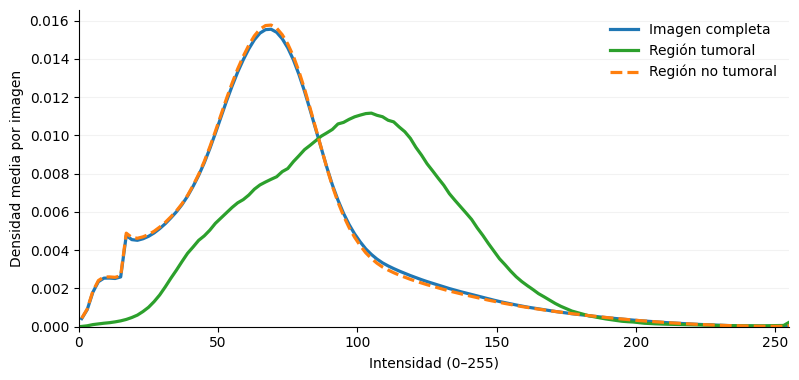

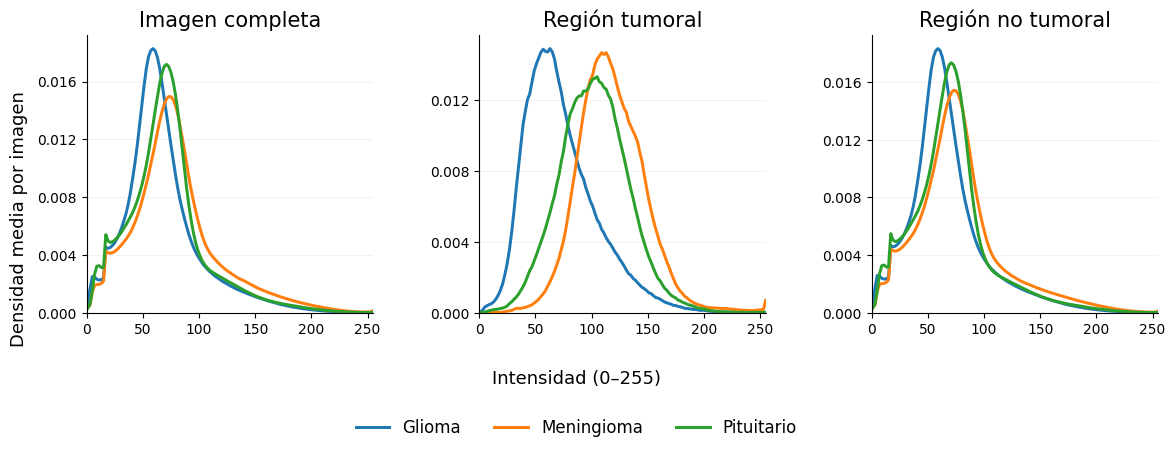

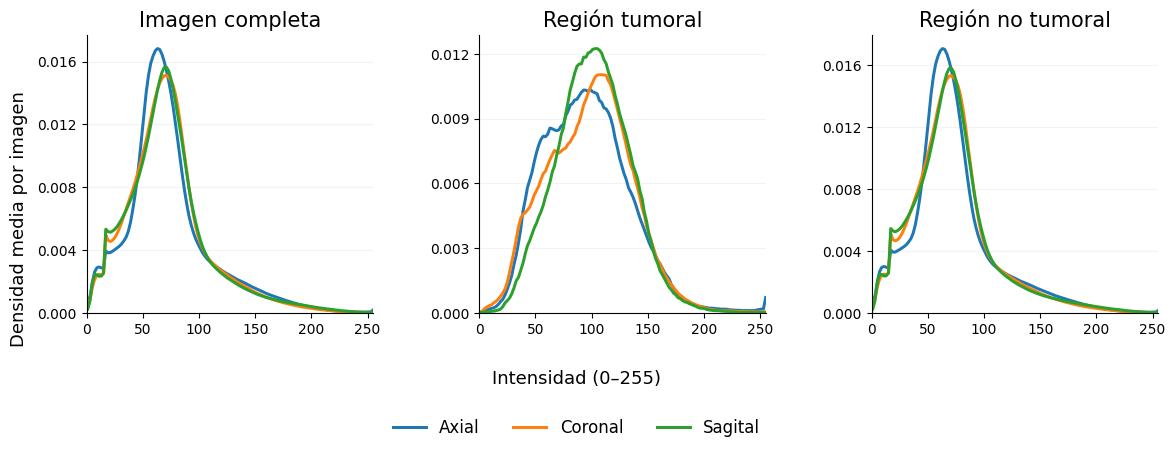

Figuras guardadas en: K:\Tesis\Github\results\OE1\analisis_distribucional_DISCO\figuras


In [19]:

from matplotlib.ticker import MaxNLocator

# ============================================================
# 1. RUTAS
# ============================================================

BASE = OUTPUT_DIR

CSV = BASE / "tablas" / "curvas_densidad_histogramas_medios.csv"
OUT = BASE / "figuras"
OUT.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(CSV)

regiones = [
    ("complete", "Imagen completa"),
    ("tumor", "Región tumoral"),
    ("non_tumor", "Región no tumoral")
]

colores = {
    "Glioma": "#1f77b4",
    "Meningioma": "#ff7f0e",
    "Pituitario": "#2ca02c",
    "Axial": "#1f77b4",
    "Coronal": "#ff7f0e",
    "Sagital": "#2ca02c",
    "Imagen completa": "#1f77b4",
    "Región tumoral": "#2ca02c",
    "Región no tumoral": "#ff7f0e"
}

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "pdf.fonttype": 42,
    "axes.spines.top": False,
    "axes.spines.right": False
})

def guardar(fig, nombre):
    fig.savefig(OUT / f"{nombre}.pdf",
                bbox_inches="tight", pad_inches=0.10)
    fig.savefig(OUT / f"{nombre}.png",
                dpi=300, bbox_inches="tight",
                pad_inches=0.10)
    plt.show()
    plt.close(fig)


# ============================================================
# 2. DISTRIBUCIONES GLOBALES
# ============================================================

fig, ax = plt.subplots(figsize=(8.1, 3.9))

for region, etiqueta in regiones:

    datos = df[
        (df["grouping"] == "global") &
        (df["region"] == region)
    ].sort_values("intensity")

    ax.plot(
        datos["intensity"],
        datos["density"],
        label=etiqueta,
        color=colores[etiqueta],
        linewidth=2.3,
        linestyle="--" if region == "non_tumor" else "-"
    )

ax.set(
    xlim=(0, 255),
    xlabel="Intensidad (0–255)",
    ylabel="Densidad media por imagen"
)
ax.set_ylim(bottom=0)
ax.grid(axis="y", alpha=0.16)
ax.legend(frameon=False)

fig.tight_layout()
guardar(fig, "intensidades_globales")


# ============================================================
# 3. PANELES POR TIPO DE TUMOR Y PLANO ANATÓMICO
# ============================================================

def generar_paneles(factor, grupos, nombre_archivo):

    fig, axes = plt.subplots(
        1, 3, figsize=(11.8, 4.7)
    )

    for ax, (region, titulo) in zip(axes, regiones):

        for grupo in grupos:

            datos = df[
                (df["grouping"] == factor) &
                (df["region"] == region) &
                (df["group"] == grupo)
            ].sort_values("intensity")

            ax.plot(
                datos["intensity"],
                datos["density"],
                label=grupo,
                color=colores[grupo],
                linewidth=2.15
            )

        ax.set_title(titulo, fontsize=15)
        ax.set_xlim(0, 255)
        ax.set_ylim(bottom=0)
        ax.set_xticks([0, 50, 100, 150, 200, 250])
        ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
        ax.grid(axis="y", alpha=0.16)

    fig.supxlabel(
        "Intensidad (0–255)",
        fontsize=13,
        y=0.14
    )
    fig.supylabel(
        "Densidad media por imagen",
        fontsize=13,
        x=0.02
    )

    handles, labels = axes[0].get_legend_handles_labels()

    fig.legend(
        handles, labels,
        loc="lower center",
        ncol=3,
        frameon=False,
        fontsize=12,
        bbox_to_anchor=(0.5, 0.005)
    )

    fig.subplots_adjust(
        left=0.085,
        right=0.993,
        top=0.89,
        bottom=0.30,
        wspace=0.37
    )

    guardar(fig, nombre_archivo)


# Figura 2: tipo de tumor
generar_paneles(
    factor="tumor_type",
    grupos=["Glioma", "Meningioma", "Pituitario"],
    nombre_archivo="intensidades_por_tipo_tumor"
)

# Figura 3: plano anatómico
generar_paneles(
    factor="plane",
    grupos=["Axial", "Coronal", "Sagital"],
    nombre_archivo="intensidades_por_plano"
)

print(f"Figuras guardadas en: {OUT}")
